In [1]:
import os

NOTEBOOK_NAME = 'TrainingFullClassOutputs'
# Mendukung eksekusi di lingkungan WSL (/mnt/d/...) maupun Windows lokal (D:/...)
if os.path.exists('/mnt/d/Projects/SIBI Recognition Lecturers/Backend/notebooks'):
    BASE_DIR = f'/mnt/d/Projects/SIBI Recognition Lecturers/Backend/notebooks/{NOTEBOOK_NAME}'
elif os.path.exists('D:/Projects/SIBI Recognition Lecturers/Backend/notebooks'):
    BASE_DIR = f'D:/Projects/SIBI Recognition Lecturers/Backend/notebooks/{NOTEBOOK_NAME}'
else:
    BASE_DIR = os.path.abspath(NOTEBOOK_NAME)

os.makedirs(BASE_DIR, exist_ok=True)
os.chdir(BASE_DIR)
print('Working directory sekarang:', os.getcwd())

Working directory sekarang: /mnt/d/Projects/SIBI Recognition Lecturers/Backend/notebooks/TrainingFullClassOutputs


In [2]:
%pip install -q numpy==1.26.4 tensorflow==2.17.0 matplotlib==3.9.4 scikit-learn==1.5.2 protobuf==4.25.3


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

from keras.utils import to_categorical
from keras.models import Model
from keras.layers import (
    Input, Dense, Dropout, BatchNormalization,
    Bidirectional, LSTM, Layer, GaussianNoise
)
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from keras.regularizers import l2

# ====== KONFIGURASI EKSPERIMEN — UBAH DI SINI SAJA ======
import datetime

N_EPOCHS = 500
RUN_TIMESTAMP = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
PATH_CONFIGURATION_GENERAL = f'Epoch{N_EPOCHS}_{RUN_TIMESTAMP}'
os.makedirs(PATH_CONFIGURATION_GENERAL, exist_ok=True)
print(f'Output eksperimen ini akan disimpan ke folder: {PATH_CONFIGURATION_GENERAL}')
# ==========================================================

print(f'TensorFlow  : {tf.__version__}')
print(f'Keras       : {tf.keras.__version__}')
print(f'GPU tersedia: {tf.config.list_physical_devices("GPU")}')

2026-10-29 14:40:53.248307: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-29 14:40:53.329945: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-29 14:40:53.375666: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-29 14:40:53.384053: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-29 14:40:53.443546: I tensorflow/core/platform/cpu_feature_guar

Output eksperimen ini akan disimpan ke folder: Epoch500_20261029_144056
TensorFlow  : 2.17.0
Keras       : 3.12.4
GPU tersedia: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


I0000 00:00:1793259656.780301   76973 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1793259657.034159   76973 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1793259657.034204   76973 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


In [4]:
# HANYA menggunakan KeypointsUpdate (hasil ekstraksi baru yang bersih)
if os.path.exists('/mnt/d/Projects/SIBI Recognition Lecturers/KeypointsUpdate'):
    DATA_PATH = '/mnt/d/Projects/SIBI Recognition Lecturers/KeypointsUpdate'
elif os.path.exists('D:/Projects/SIBI Recognition Lecturers/KeypointsUpdate'):
    DATA_PATH = 'D:/Projects/SIBI Recognition Lecturers/KeypointsUpdate'
else:
    DATA_PATH = os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'KeypointsUpdate'))

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Folder KeypointsUpdate tidak ditemukan di: {DATA_PATH}. Jalankan extract_keypoints_from_video.py terlebih dahulu!")

print('Menggunakan DATA_PATH:', DATA_PATH)

sequence_length = 30
FITUR_PER_FRAME = 258
MODEL_OUTPUT    = f'{PATH_CONFIGURATION_GENERAL}/modelFullClass.keras'
MODEL_OUTPUT_H5  = f'{PATH_CONFIGURATION_GENERAL}/modelFullClass.h5'
TEMP_CHECKPOINT = f'{PATH_CONFIGURATION_GENERAL}/temp_checkpoint.keras'

actions = np.array([
    'Adik', 'Apa', 'Ayah', 'Baik', 'Berapa', 'Bertemu', 'Cantik', 'Dari',
    'Dia', 'Dimana', 'Ganteng', 'Gemuk', 'Hallo', 'Hobi', 'Ibu', 'Jumat',
    'Jurusan', 'Kabar', 'Kakak', 'Kalian', 'Kami', 'Kamis', 'Kampus', 'Kamu',
    'Kelas', 'Keluarga', 'Kemana', 'Kenapa', 'Kita', 'Kuliah', 'Kurus', 'Lucu',
    'Malam', 'Mau', 'Mereka', 'Minggu', 'Nama', 'Pagi', 'Pelit', 'Pendidikan',
    'Pintar', 'Pulang', 'Rabu', 'Ramah', 'Rendah Hati', 'Sabar', 'Sabtu', 'Sakit',
    'Sampai Jumpa', 'Saya', 'Sekolah', 'Selamat', 'Selasa', 'Semester', 'Senang', 'Senin',
    'Siang', 'Siapa', 'Sore', 'Suka', 'Terimakasih', 'Tinggal', 'Umur'
])
POSE_DIM   = 132
LH_DIM     = 63
RH_DIM     = 63
POSE_END   = POSE_DIM
LH_END     = POSE_END + LH_DIM
RH_END     = LH_END + RH_DIM

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('Kelas yang dilatih :', actions)
print('Jumlah kelas        :', len(actions))
print('Sequence length     :', sequence_length)
print('Fitur per frame     :', FITUR_PER_FRAME)
print('  - Pose : 0..{}    (132 = 33 x 4)'.format(POSE_END - 1))
print('  - LH   : {}..{}  (63 = 21 x 3)'.format(POSE_END, LH_END - 1))
print('  - RH   : {}..{}  (63 = 21 x 3)'.format(LH_END, RH_END - 1))
print('Output model        :', MODEL_OUTPUT)

os.makedirs(os.path.dirname(MODEL_OUTPUT), exist_ok=True)
os.makedirs(os.path.dirname(TEMP_CHECKPOINT), exist_ok=True)
print('✅ Folder output siap:', os.path.dirname(MODEL_OUTPUT))

Menggunakan DATA_PATH: /mnt/d/Projects/SIBI Recognition Lecturers/KeypointsUpdate
Kelas yang dilatih : ['Adik' 'Apa' 'Ayah' 'Baik' 'Berapa' 'Bertemu' 'Cantik' 'Dari' 'Dia'
 'Dimana' 'Ganteng' 'Gemuk' 'Hallo' 'Hobi' 'Ibu' 'Jumat' 'Jurusan' 'Kabar'
 'Kakak' 'Kalian' 'Kami' 'Kamis' 'Kampus' 'Kamu' 'Kelas' 'Keluarga'
 'Kemana' 'Kenapa' 'Kita' 'Kuliah' 'Kurus' 'Lucu' 'Malam' 'Mau' 'Mereka'
 'Minggu' 'Nama' 'Pagi' 'Pelit' 'Pendidikan' 'Pintar' 'Pulang' 'Rabu'
 'Ramah' 'Rendah Hati' 'Sabar' 'Sabtu' 'Sakit' 'Sampai Jumpa' 'Saya'
 'Sekolah' 'Selamat' 'Selasa' 'Semester' 'Senang' 'Senin' 'Siang' 'Siapa'
 'Sore' 'Suka' 'Terimakasih' 'Tinggal' 'Umur']
Jumlah kelas        : 63
Sequence length     : 30
Fitur per frame     : 258
  - Pose : 0..131    (132 = 33 x 4)
  - LH   : 132..194  (63 = 21 x 3)
  - RH   : 195..257  (63 = 21 x 3)
Output model        : Epoch500_20261029_144056/modelFullClass.keras
✅ Folder output siap: Epoch500_20261029_144056


In [5]:
label_map = {label: num for num, label in enumerate(actions)}
print('Label map:', label_map)

sequences, labels = [], []

for action in actions:
    action_path = os.path.join(DATA_PATH, action)

    if not os.path.exists(action_path):
        print(f'⚠️  Folder tidak ditemukan: {action_path}')
        continue

    sequence_folders = sorted(
        [f for f in os.listdir(action_path) if f.isdigit()],
        key=int
    )

    loaded, skipped = 0, 0
    for sequence in sequence_folders:
        window = []
        try:
            for frame_num in range(sequence_length):
                res = np.load(os.path.join(action_path, sequence, f'{frame_num}.npy'))
                if res.shape[0] != FITUR_PER_FRAME:
                    raise ValueError(f'Fitur {res.shape[0]} != {FITUR_PER_FRAME} — cek extract_keypoints!')
                window.append(res)
            sequences.append(np.array(window))
            labels.append(label_map[action])
            loaded += 1
        except Exception:
            skipped += 1

    print(f'  {action:12s}: {loaded} dimuat, {skipped} dilewati')

X     = np.array(sequences, dtype=np.float32)
y_int = np.array(labels)
y     = to_categorical(y_int, num_classes=len(actions))

print(f'\n✅ Shape X : {X.shape}')
print(f'✅ Shape y : {y.shape}')
print('\nDistribusi kelas:')
for u, c in zip(*np.unique(y_int, return_counts=True)):
    print(f'  {actions[u]:12s}: {c} sequence')

Label map: {'Adik': 0, 'Apa': 1, 'Ayah': 2, 'Baik': 3, 'Berapa': 4, 'Bertemu': 5, 'Cantik': 6, 'Dari': 7, 'Dia': 8, 'Dimana': 9, 'Ganteng': 10, 'Gemuk': 11, 'Hallo': 12, 'Hobi': 13, 'Ibu': 14, 'Jumat': 15, 'Jurusan': 16, 'Kabar': 17, 'Kakak': 18, 'Kalian': 19, 'Kami': 20, 'Kamis': 21, 'Kampus': 22, 'Kamu': 23, 'Kelas': 24, 'Keluarga': 25, 'Kemana': 26, 'Kenapa': 27, 'Kita': 28, 'Kuliah': 29, 'Kurus': 30, 'Lucu': 31, 'Malam': 32, 'Mau': 33, 'Mereka': 34, 'Minggu': 35, 'Nama': 36, 'Pagi': 37, 'Pelit': 38, 'Pendidikan': 39, 'Pintar': 40, 'Pulang': 41, 'Rabu': 42, 'Ramah': 43, 'Rendah Hati': 44, 'Sabar': 45, 'Sabtu': 46, 'Sakit': 47, 'Sampai Jumpa': 48, 'Saya': 49, 'Sekolah': 50, 'Selamat': 51, 'Selasa': 52, 'Semester': 53, 'Senang': 54, 'Senin': 55, 'Siang': 56, 'Siapa': 57, 'Sore': 58, 'Suka': 59, 'Terimakasih': 60, 'Tinggal': 61, 'Umur': 62}
  Adik        : 101 dimuat, 0 dilewati
  Apa         : 100 dimuat, 0 dilewati
  Ayah        : 97 dimuat, 0 dilewati
  Baik        : 99 dimuat, 0 di

In [6]:
X_train_raw, X_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    X, y_int, test_size=0.30, random_state=SEED, stratify=y_int
)
X_val_raw, X_test_raw, y_val_raw, y_test_raw = train_test_split(
    X_temp_raw, y_temp_raw, test_size=0.50, random_state=SEED, stratify=y_temp_raw
)

print(f'Train (asli) : {X_train_raw.shape[0]} sequence')
print(f'Val   (asli) : {X_val_raw.shape[0]} sequence')
print(f'Test  (asli) : {X_test_raw.shape[0]} sequence')
print('\nDistribusi train asli:')
for u, c in zip(*np.unique(y_train_raw, return_counts=True)):
    print(f'  {actions[u]:12s}: {c}')

Train (asli) : 4409 sequence
Val   (asli) : 945 sequence
Test  (asli) : 945 sequence

Distribusi train asli:
  Adik        : 71
  Apa         : 70
  Ayah        : 68
  Baik        : 69
  Berapa      : 71
  Bertemu     : 71
  Cantik      : 69
  Dari        : 71
  Dia         : 70
  Dimana      : 70
  Ganteng     : 69
  Gemuk       : 69
  Hallo       : 71
  Hobi        : 71
  Ibu         : 71
  Jumat       : 73
  Jurusan     : 71
  Kabar       : 71
  Kakak       : 34
  Kalian      : 70
  Kami        : 71
  Kamis       : 69
  Kampus      : 70
  Kamu        : 70
  Kelas       : 73
  Keluarga    : 70
  Kemana      : 69
  Kenapa      : 74
  Kita        : 65
  Kuliah      : 69
  Kurus       : 70
  Lucu        : 69
  Malam       : 70
  Mau         : 73
  Mereka      : 71
  Minggu      : 70
  Nama        : 71
  Pagi        : 69
  Pelit       : 70
  Pendidikan  : 70
  Pintar      : 69
  Pulang      : 70
  Rabu        : 69
  Ramah       : 90
  Rendah Hati : 71
  Sabar       : 74
  Sabtu       : 7

In [7]:
def split_features(seq):
    """Pisah seq (T, 258) → pose (T, 33, 4), lh (T, 21, 3), rh (T, 21, 3)."""
    pose = seq[:, :POSE_END].reshape(-1, 33, 4)
    lh   = seq[:, POSE_END:LH_END].reshape(-1, 21, 3)
    rh   = seq[:, LH_END:RH_END].reshape(-1, 21, 3)
    return pose, lh, rh


def merge_features(pose, lh, rh):
    """Gabungkan kembali ke seq (T, 258)."""
    T = pose.shape[0]
    return np.concatenate([
        pose.reshape(T, -1), lh.reshape(T, -1), rh.reshape(T, -1)
    ], axis=1).astype(np.float32)


def get_body_center(pose):
    """Ambil pusat tubuh (titik tengah bahu kiri index 11 & bahu kanan index 12)."""
    left_sh = pose[:, 11, :2]
    right_sh = pose[:, 12, :2]
    valid = (pose[:, 11, 3] > 0.1) & (pose[:, 12, 3] > 0.1)
    if np.any(valid):
        return (left_sh[valid] + right_sh[valid]).mean(axis=0) / 2.0
    return np.array([0.5, 0.5], dtype=np.float32)


def aug_zoom_half_body(seq, scale_range=(1.40, 2.05), shift_y_range=(-0.20, -0.06)):
    """
    Simulasi kamera webcam jarak dekat (setengah badan / chest-up).
    Dataset asli direkam full body (kepala-ke-lutut) sehingga tubuh tampak kecil.
    Augmentasi ini memperbesar tubuh dan tangan penutur sebesar 1.4x - 2.05x
    serta menggeser posisi ke atas frame (dy < 0) agar sesuai dengan proporsi
    pengguna yang sedang duduk setengah badan di depan laptop/webcam.
    """
    s = np.random.uniform(*scale_range)
    dy = np.random.uniform(*shift_y_range)
    pose, lh, rh = split_features(seq)
    cx, cy = get_body_center(pose)

    pose_xyz = pose[:, :, :3].copy()
    pose_xyz[:, :, 0] = cx + (pose_xyz[:, :, 0] - cx) * s
    pose_xyz[:, :, 1] = cy + (pose_xyz[:, :, 1] - cy) * s + dy
    pose_xyz[:, :, 2] = pose_xyz[:, :, 2] * s
    pose_new = np.concatenate([pose_xyz, pose[:, :, 3:4]], axis=-1)

    lh_new = lh.copy()
    if np.any(np.abs(lh) > 1e-4):
        mask = (np.abs(lh).sum(axis=-1, keepdims=True) > 1e-4)
        lh_new[:, :, 0] = (cx + (lh_new[:, :, 0] - cx) * s) * mask[:, :, 0]
        lh_new[:, :, 1] = (cy + (lh_new[:, :, 1] - cy) * s + dy) * mask[:, :, 0]
        lh_new[:, :, 2] = (lh_new[:, :, 2] * s) * mask[:, :, 0]

    rh_new = rh.copy()
    if np.any(np.abs(rh) > 1e-4):
        mask = (np.abs(rh).sum(axis=-1, keepdims=True) > 1e-4)
        rh_new[:, :, 0] = (cx + (rh_new[:, :, 0] - cx) * s) * mask[:, :, 0]
        rh_new[:, :, 1] = (cy + (rh_new[:, :, 1] - cy) * s + dy) * mask[:, :, 0]
        rh_new[:, :, 2] = (rh_new[:, :, 2] * s) * mask[:, :, 0]

    return merge_features(pose_new, lh_new, rh_new)


def aug_centered_scale(seq, scale_range=(0.85, 1.35)):
    """
    Scaling berpusat pada tubuh (bahu), BUKAN di titik (0,0) pojok layar.
    Mensimulasikan variasi jarak natural penutur saat di depan kamera.
    """
    s = np.random.uniform(*scale_range)
    pose, lh, rh = split_features(seq)
    cx, cy = get_body_center(pose)

    pose_xyz = pose[:, :, :3].copy()
    pose_xyz[:, :, 0] = cx + (pose_xyz[:, :, 0] - cx) * s
    pose_xyz[:, :, 1] = cy + (pose_xyz[:, :, 1] - cy) * s
    pose_xyz[:, :, 2] = pose_xyz[:, :, 2] * s
    pose_new = np.concatenate([pose_xyz, pose[:, :, 3:4]], axis=-1)

    lh_new = lh.copy()
    if np.any(np.abs(lh) > 1e-4):
        mask = (np.abs(lh).sum(axis=-1, keepdims=True) > 1e-4)
        lh_new[:, :, 0] = (cx + (lh_new[:, :, 0] - cx) * s) * mask[:, :, 0]
        lh_new[:, :, 1] = (cy + (lh_new[:, :, 1] - cy) * s) * mask[:, :, 0]
        lh_new[:, :, 2] = (lh_new[:, :, 2] * s) * mask[:, :, 0]

    rh_new = rh.copy()
    if np.any(np.abs(rh) > 1e-4):
        mask = (np.abs(rh).sum(axis=-1, keepdims=True) > 1e-4)
        rh_new[:, :, 0] = (cx + (rh_new[:, :, 0] - cx) * s) * mask[:, :, 0]
        rh_new[:, :, 1] = (cy + (rh_new[:, :, 1] - cy) * s) * mask[:, :, 0]
        rh_new[:, :, 2] = (rh_new[:, :, 2] * s) * mask[:, :, 0]

    return merge_features(pose_new, lh_new, rh_new)


def aug_gaussian_noise(seq, sigma=0.007):
    """
    Noise ringan pada x,y,z titik yang terdeteksi.
    PENTING: Tangan yang tidak terdeteksi (all zeros) TIDAK diberi noise
    agar tidak menghasilkan koordinat tangan palsu/hantu (phantom landmarks).
    """
    pose, lh, rh = split_features(seq)
    pose_xyz = pose[:, :, :3] + np.random.normal(0, sigma, pose[:, :, :3].shape)
    pose_new = np.concatenate([pose_xyz, pose[:, :, 3:4]], axis=-1)

    lh_new = lh.copy()
    if np.any(np.abs(lh) > 1e-4):
        lh_mask = (np.abs(lh).sum(axis=-1, keepdims=True) > 1e-4)
        lh_new += np.random.normal(0, sigma, lh.shape) * lh_mask

    rh_new = rh.copy()
    if np.any(np.abs(rh) > 1e-4):
        rh_mask = (np.abs(rh).sum(axis=-1, keepdims=True) > 1e-4)
        rh_new += np.random.normal(0, sigma, rh.shape) * rh_mask

    return merge_features(pose_new, lh_new, rh_new)


def aug_translation(seq, shift_range=0.08):
    """
    Translasi x,y lebih realistis (hingga +-8% layar).
    Mensimulasikan posisi duduk pengguna saat live webcam (agak ke kiri/kanan/atas/bawah).
    """
    dx = np.random.uniform(-shift_range, shift_range)
    dy = np.random.uniform(-shift_range, shift_range)
    pose, lh, rh = split_features(seq)

    pose_xyz = pose[:, :, :3].copy()
    pose_xyz[:, :, 0] += dx
    pose_xyz[:, :, 1] += dy
    pose_new = np.concatenate([pose_xyz, pose[:, :, 3:4]], axis=-1)

    lh_new = lh.copy()
    if np.any(np.abs(lh) > 1e-4):
        mask = (np.abs(lh).sum(axis=-1, keepdims=True) > 1e-4)
        lh_new[:, :, 0] = (lh_new[:, :, 0] + dx) * mask[:, :, 0]
        lh_new[:, :, 1] = (lh_new[:, :, 1] + dy) * mask[:, :, 0]

    rh_new = rh.copy()
    if np.any(np.abs(rh) > 1e-4):
        mask = (np.abs(rh).sum(axis=-1, keepdims=True) > 1e-4)
        rh_new[:, :, 0] = (rh_new[:, :, 0] + dx) * mask[:, :, 0]
        rh_new[:, :, 1] = (rh_new[:, :, 1] + dy) * mask[:, :, 0]

    return merge_features(pose_new, lh_new, rh_new)


def aug_time_warp(seq, factor_range=(0.80, 1.20)):
    """
    Time warping: mensimulasikan penutur yang melakukan isyarat lebih cepat atau lambat.
    """
    factor = np.random.uniform(*factor_range)
    T = seq.shape[0]
    new_T = max(2, int(T * factor))
    old_x = np.linspace(0, 1, T)
    new_x = np.linspace(0, 1, new_T)
    intermediate = np.array([
        np.interp(new_x, old_x, seq[:, fi]) for fi in range(seq.shape[1])
    ]).T
    final = np.array([
        np.interp(old_x, new_x, intermediate[:, fi]) for fi in range(seq.shape[1])
    ]).T
    return final.astype(np.float32)


def aug_hand_dropout(seq, max_drop_frames=3):
    """
    Simulasi kedipan deteksi (tracking flicker) MediaPipe di browser.
    Secara acak menghilangkan deteksi tangan kanan pada 1-3 frame.
    Membuat BiLSTM tangguh saat terjadi occlusion sesaat di webcam.
    """
    pose, lh, rh = split_features(seq)
    T = seq.shape[0]
    n_drop = np.random.randint(1, max_drop_frames + 1)
    drop_idx = np.random.choice(T, n_drop, replace=False)
    rh_new = rh.copy()
    rh_new[drop_idx] = 0.0
    return merge_features(pose, lh, rh_new)


def aug_visibility_variation(seq):
    """
    Simulasi MediaPipe JavaScript di browser yang sering kehilangan nilai visibility.
    Memvariasikan dan men-drop sebagian visibility agar model BiLSTM belajar murni
    dari geometri gerakan tangan & tubuh, bukan bergantung pada flag visibility python.
    """
    pose, lh, rh = split_features(seq)
    vis = pose[:, :, 3].copy()
    scale = np.random.uniform(0.2, 1.0)
    vis = vis * scale
    mask = np.random.binomial(1, 0.8, size=vis.shape)
    vis = vis * mask
    pose_new = np.concatenate([pose[:, :, :3], vis[:, :, np.newaxis]], axis=-1)
    return merge_features(pose_new, lh, rh)


def aug_slight_rotation(seq, max_angle_deg=6):
    """
    Rotasi kecil (+-6 derajat) terhadap titik tengah tubuh (bahu).
    Mensimulasikan kemiringan posisi duduk atau sudut kamera webcam.
    """
    angle = np.radians(np.random.uniform(-max_angle_deg, max_angle_deg))
    cos_a, sin_a = np.cos(angle), np.sin(angle)
    pose, lh, rh = split_features(seq)
    cx, cy = get_body_center(pose)

    def rotate_xy(arr):
        x, y = arr[:, :, 0] - cx, arr[:, :, 1] - cy
        rx = x * cos_a - y * sin_a + cx
        ry = x * sin_a + y * cos_a + cy
        out = arr.copy()
        out[:, :, 0], out[:, :, 1] = rx, ry
        return out

    pose_xyz = rotate_xy(pose[:, :, :3])
    pose_new = np.concatenate([pose_xyz, pose[:, :, 3:4]], axis=-1)

    lh_new = lh.copy()
    if np.any(np.abs(lh) > 1e-4):
        mask = (np.abs(lh).sum(axis=-1, keepdims=True) > 1e-4)
        rotated_lh = rotate_xy(lh)
        lh_new = rotated_lh * mask

    rh_new = rh.copy()
    if np.any(np.abs(rh) > 1e-4):
        mask = (np.abs(rh).sum(axis=-1, keepdims=True) > 1e-4)
        rotated_rh = rotate_xy(rh)
        rh_new = rotated_rh * mask

    return merge_features(pose_new, lh_new, rh_new)


def augment_sequence(seq, label_idx):
    """
    Daftar augmentasi khusus tangan kanan (dominant right hand) & multi-jarak:
    - TIDAK ada swap tangan kiri/kanan (aug_mirror_hands dihapus).
    - TIDAK ada koordinat negatif (-x).
    - Menangani perbedaan sudut/jarak kamera:
      1) aug_zoom_half_body: Zoom 1.4x-2.05x (jarak dekat / setengah badan khas webcam)
      2) aug_centered_scale: Variasi jarak natural 0.85x-1.35x
      3) aug_translation: Pergeseran posisi duduk/berdiri +-8%
      4) aug_time_warp: Variasi kecepatan isyarat 0.80x-1.20x
      5) aug_hand_dropout: Kedipan deteksi tangan 1-3 frame
      6) aug_visibility_variation: Variasi visibility MediaPipe browser
      7) aug_slight_rotation: Kemiringan kamera +-6 derajat
      8) aug_gaussian_noise: Noise sensor ringan
    """
    augs = [
        aug_zoom_half_body(seq),        # Zoom setengah badan (webcam laptop jarak dekat)
        aug_centered_scale(seq),        # Skala natural (0.85 - 1.35)
        aug_translation(seq),           # Posisi duduk
        aug_time_warp(seq),             # Kecepatan isyarat
        aug_hand_dropout(seq),          # Tahan tracking flicker
        aug_visibility_variation(seq),  # Tahan browser visibility drop
        aug_slight_rotation(seq),       # Kemiringan sudut webcam
        aug_gaussian_noise(seq),        # Noise sensor
    ]
    return augs


print('Melakukan augmentasi (HANYA pada train set)...')
X_train_aug_list = list(X_train_raw)
y_train_aug_list = list(y_train_raw)

for seq, lbl in zip(X_train_raw, y_train_raw):
    for aug_seq in augment_sequence(seq, lbl):
        X_train_aug_list.append(aug_seq)
        y_train_aug_list.append(lbl)

X_train = np.array(X_train_aug_list, dtype=np.float32)
y_train_int = np.array(y_train_aug_list)
y_train = to_categorical(y_train_int, num_classes=len(actions))

# Val & test TIDAK diaugmentasi (hanya konversi ke categorical)
X_val  = X_val_raw.astype(np.float32)
y_val  = to_categorical(y_val_raw, num_classes=len(actions))
X_test = X_test_raw.astype(np.float32)
y_test = to_categorical(y_test_raw, num_classes=len(actions))

print(f'\n✅ Train (setelah augmentasi) : {X_train.shape[0]}')
print(f'✅ Val                          : {X_val.shape[0]} (TIDAK diaugmentasi)')
print(f'✅ Test                         : {X_test.shape[0]} (TIDAK diaugmentasi)')

print('\nDistribusi kelas TRAIN setelah augmentasi:')
for u, c in zip(*np.unique(y_train_int, return_counts=True)):
    print(f'  {actions[u]:12s}: {c}')


Melakukan augmentasi (HANYA pada train set)...

✅ Train (setelah augmentasi) : 39681
✅ Val                          : 945 (TIDAK diaugmentasi)
✅ Test                         : 945 (TIDAK diaugmentasi)

Distribusi kelas TRAIN setelah augmentasi:
  Adik        : 639
  Apa         : 630
  Ayah        : 612
  Baik        : 621
  Berapa      : 639
  Bertemu     : 639
  Cantik      : 621
  Dari        : 639
  Dia         : 630
  Dimana      : 630
  Ganteng     : 621
  Gemuk       : 621
  Hallo       : 639
  Hobi        : 639
  Ibu         : 639
  Jumat       : 657
  Jurusan     : 639
  Kabar       : 639
  Kakak       : 306
  Kalian      : 630
  Kami        : 639
  Kamis       : 621
  Kampus      : 630
  Kamu        : 630
  Kelas       : 657
  Keluarga    : 630
  Kemana      : 621
  Kenapa      : 666
  Kita        : 585
  Kuliah      : 621
  Kurus       : 630
  Lucu        : 621
  Malam       : 630
  Mau         : 657
  Mereka      : 639
  Minggu      : 630
  Nama        : 639
  Pagi        :

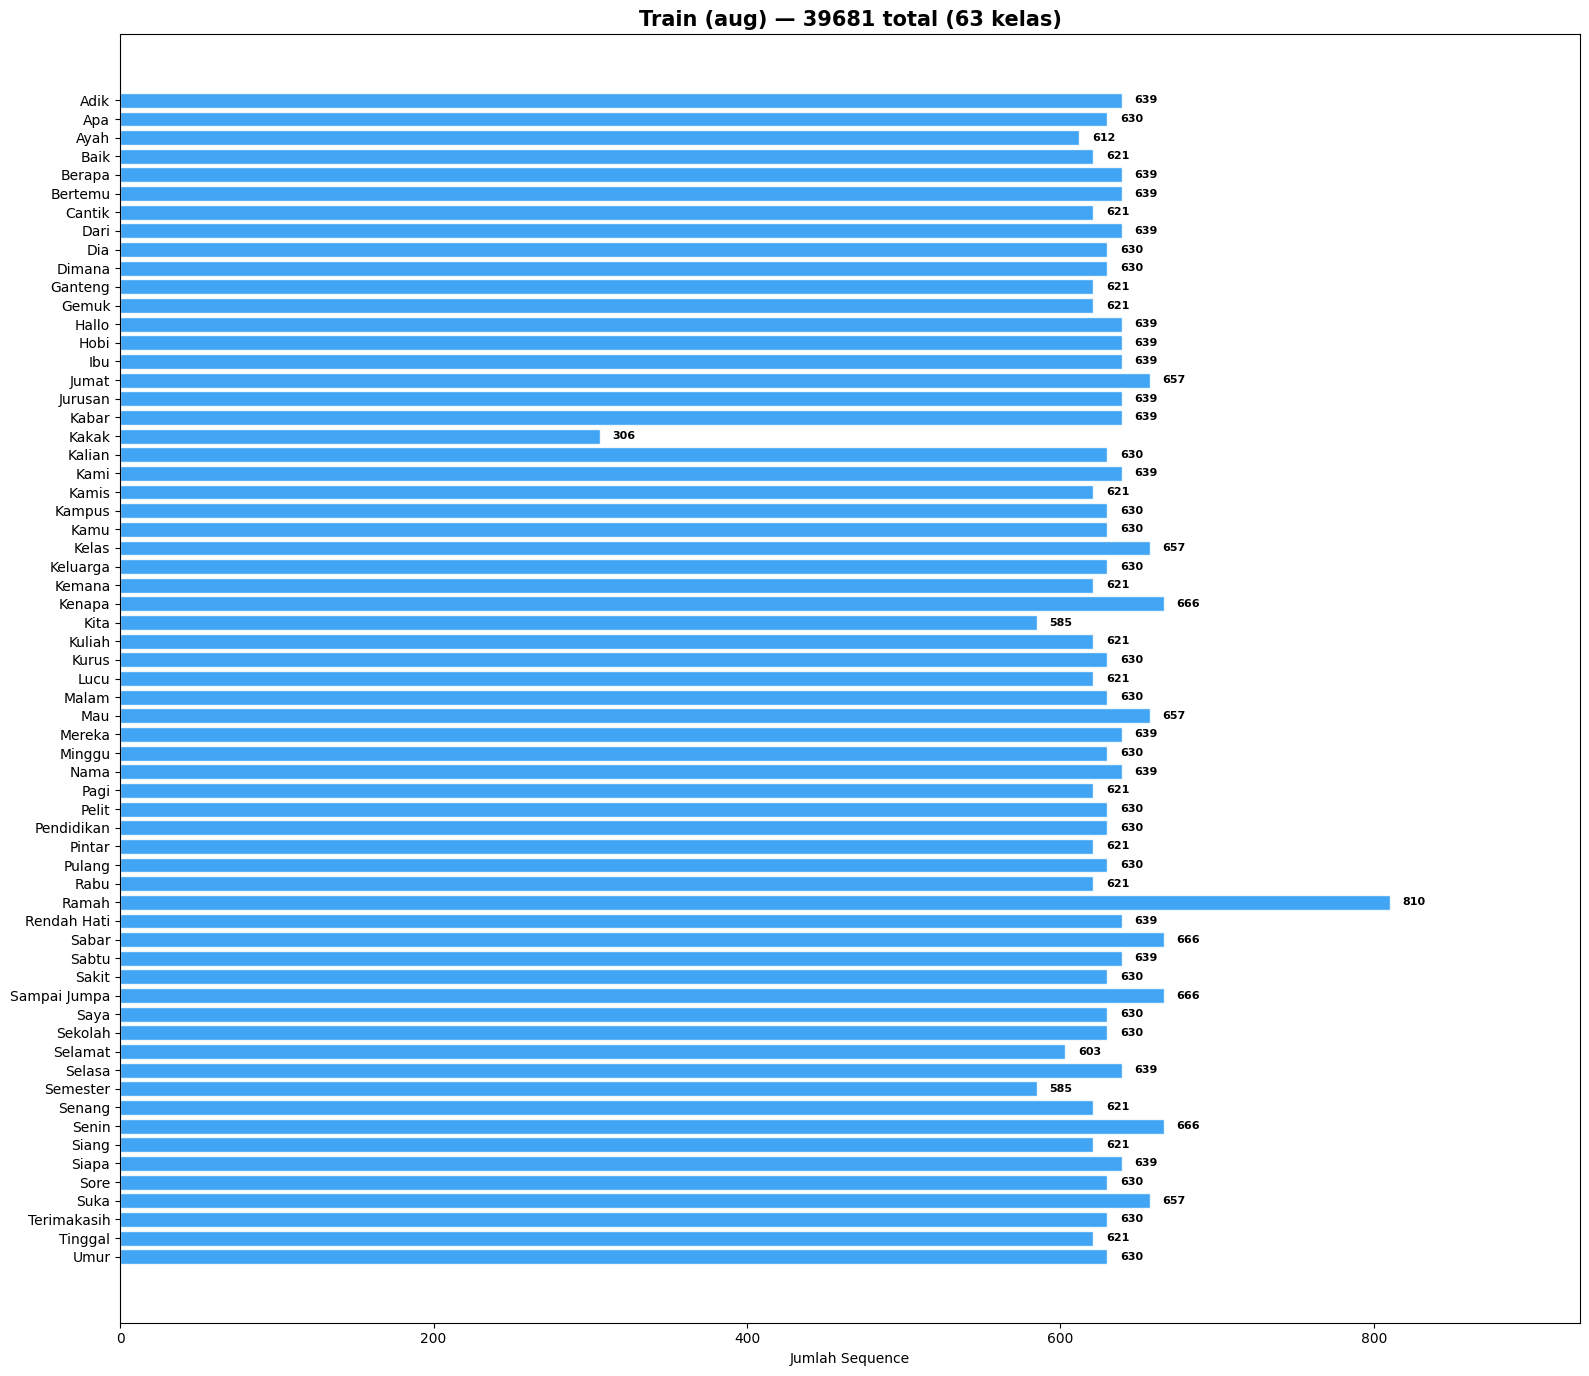

In [8]:
n = len(actions)
fig, ax = plt.subplots(figsize=(16, max(10, n * 0.22)))
counts = np.sum(y_train, axis=0).astype(int)
bars = ax.barh(actions, counts, color='#2196F3', alpha=0.85, edgecolor='white')
ax.set_title(f'Train (aug) — {y_train.shape[0]} total ({n} kelas)', fontweight='bold', fontsize=15)
ax.set_xlabel('Jumlah Sequence')
ax.set_xlim(0, max(counts) * 1.15)
ax.invert_yaxis()

for bar, c in zip(bars, counts):
    ax.text(bar.get_width() + max(counts)*0.01, bar.get_y() + bar.get_height()/2,
            str(c), va='center', fontweight='bold', fontsize=8)

plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_distribusi_train.png', dpi=200, bbox_inches='tight')
plt.show()

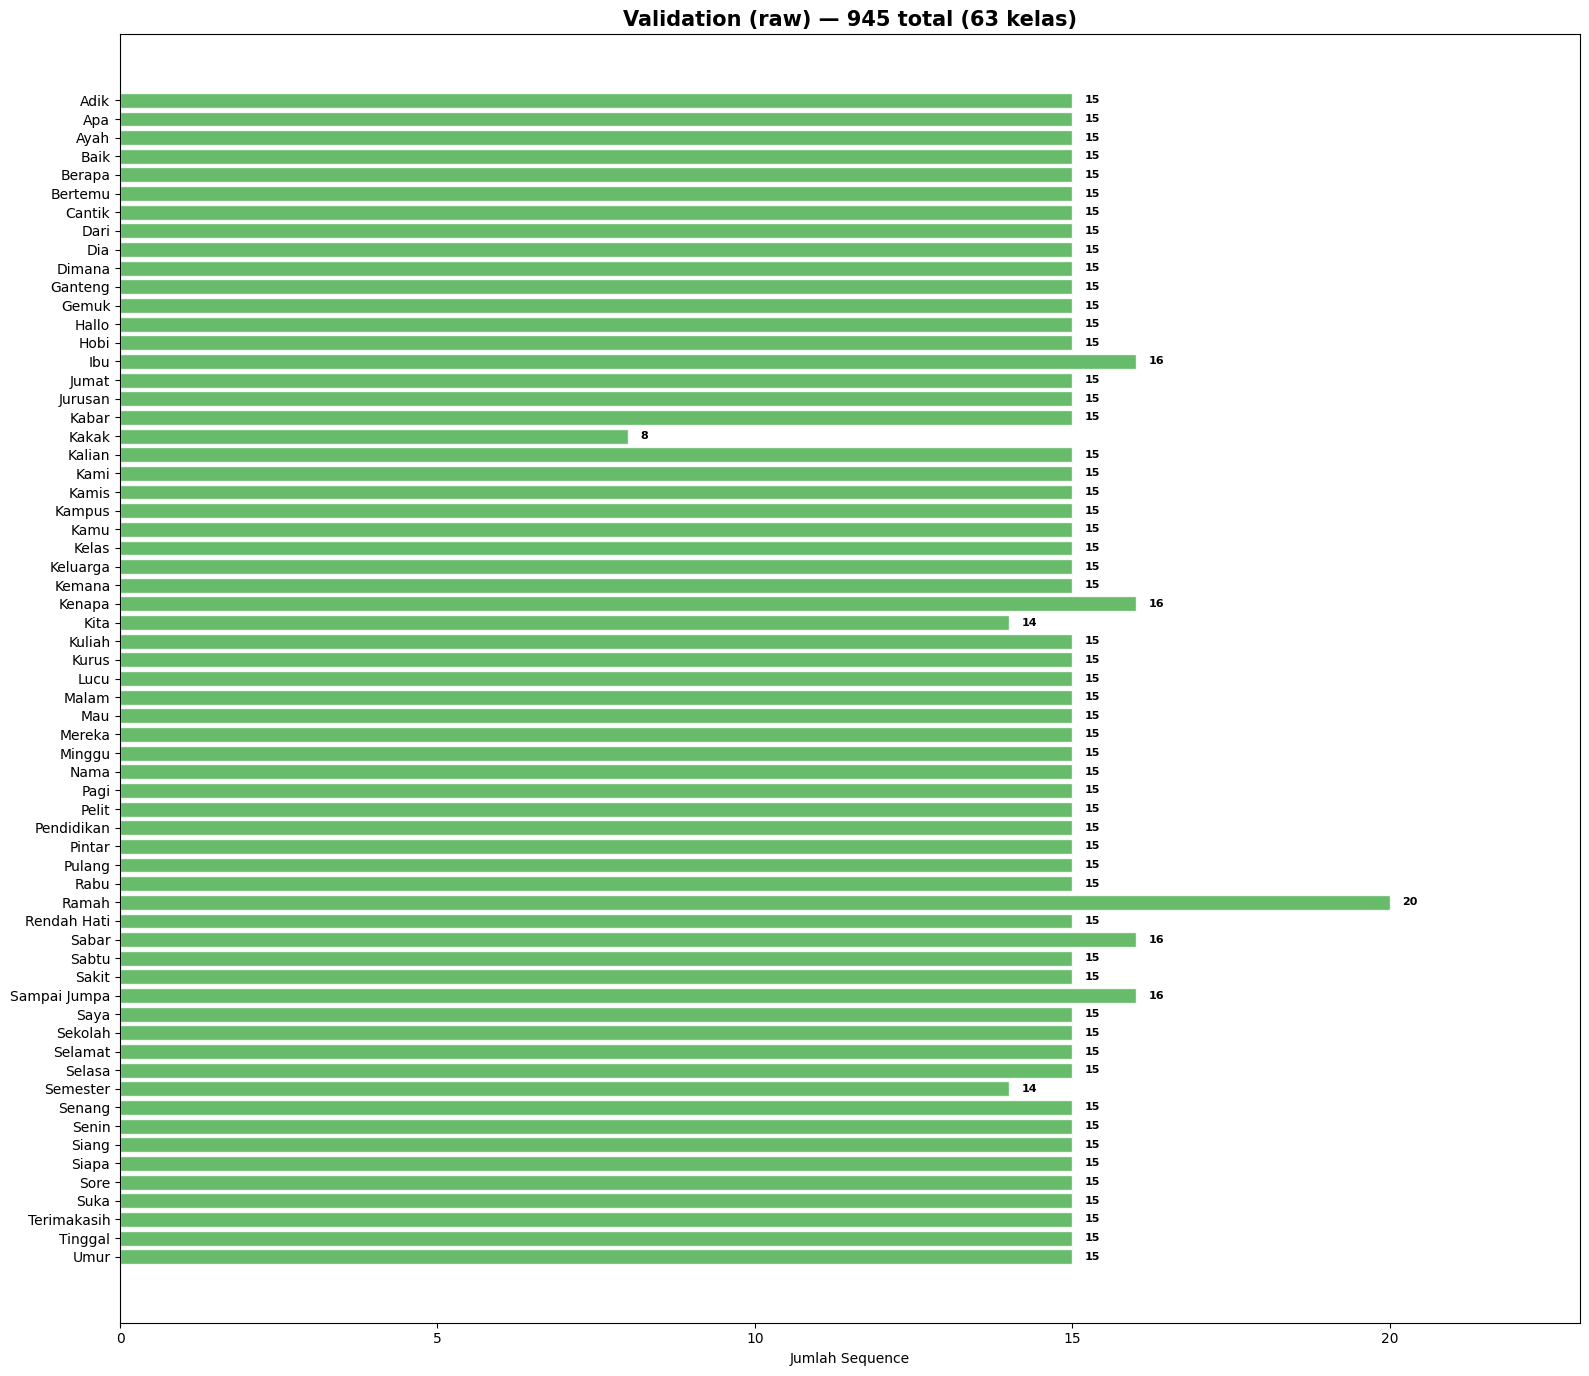

In [9]:
n = len(actions)
fig, ax = plt.subplots(figsize=(16, max(10, n * 0.22)))
counts = np.sum(y_val, axis=0).astype(int)
bars = ax.barh(actions, counts, color='#4CAF50', alpha=0.85, edgecolor='white')
ax.set_title(f'Validation (raw) — {y_val.shape[0]} total ({n} kelas)', fontweight='bold', fontsize=15)
ax.set_xlabel('Jumlah Sequence')
ax.set_xlim(0, max(counts) * 1.15)
ax.invert_yaxis()

for bar, c in zip(bars, counts):
    ax.text(bar.get_width() + max(counts)*0.01, bar.get_y() + bar.get_height()/2,
            str(c), va='center', fontweight='bold', fontsize=8)

plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_distribusi_val.png', dpi=200, bbox_inches='tight')
plt.show()

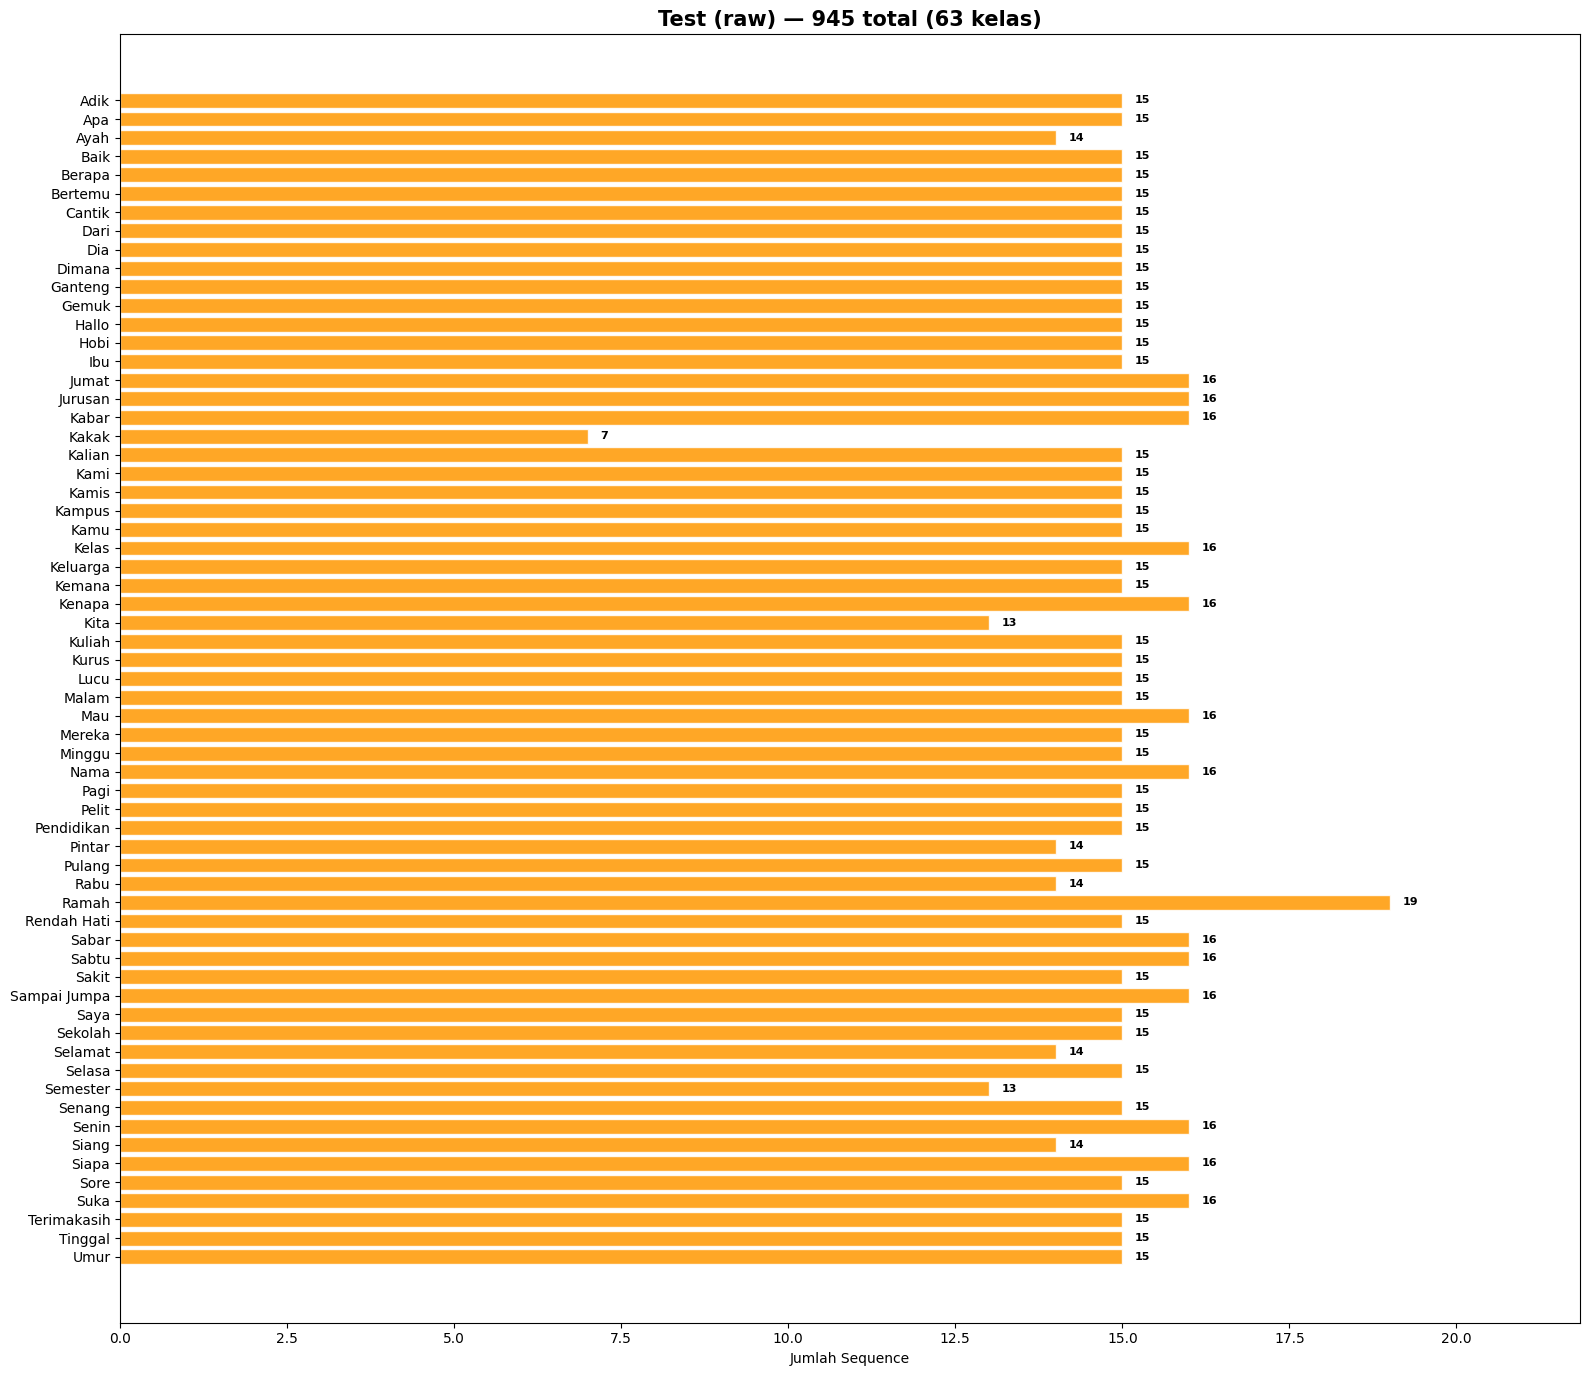

In [10]:
n = len(actions)
fig, ax = plt.subplots(figsize=(16, max(10, n * 0.22)))
counts = np.sum(y_test, axis=0).astype(int)
bars = ax.barh(actions, counts, color='#FF9800', alpha=0.85, edgecolor='white')
ax.set_title(f'Test (raw) — {y_test.shape[0]} total ({n} kelas)', fontweight='bold', fontsize=15)
ax.set_xlabel('Jumlah Sequence')
ax.set_xlim(0, max(counts) * 1.15)
ax.invert_yaxis()

for bar, c in zip(bars, counts):
    ax.text(bar.get_width() + max(counts)*0.01, bar.get_y() + bar.get_height()/2,
            str(c), va='center', fontweight='bold', fontsize=8)

plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_distribusi_test.png', dpi=200, bbox_inches='tight')
plt.show()

In [11]:
class AttentionLayer(Layer):
    def build(self, input_shape):
        self.W = self.add_weight(shape=(input_shape[-1], 1),
                                 initializer='glorot_uniform', trainable=True)
        self.b = self.add_weight(shape=(input_shape[1], 1),
                                 initializer='zeros', trainable=True)
        super().build(input_shape)

    def call(self, x):
        e = tf.nn.tanh(tf.matmul(x, self.W) + self.b)
        a = tf.nn.softmax(e, axis=1)
        return tf.reduce_sum(x * a, axis=1)

    def get_config(self):
        return super().get_config()

@tf.keras.utils.register_keras_serializable(package='custom')
class FocalLossWithSmoothing(tf.keras.losses.Loss):
    def __init__(self, gamma=2.0, alpha=None, label_smoothing=0.05,
                 name='focal_loss_with_smoothing', **kwargs):
        super().__init__(name=name, **kwargs)
        self.gamma = gamma
        self.alpha = alpha if alpha is not None else [1.0] * 63
        self.label_smoothing = label_smoothing

    def call(self, y_true, y_pred):
        n_classes = tf.shape(y_pred)[-1]
        # Label smoothing
        y_true_smooth = y_true * (1.0 - self.label_smoothing) + \
                        self.label_smoothing / tf.cast(n_classes, tf.float32)

        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        ce = -y_true_smooth * tf.math.log(y_pred)

        alpha_tensor = tf.constant(self.alpha, dtype=tf.float32)
        pt = tf.reduce_sum(y_true * y_pred, axis=-1, keepdims=True)
        alpha_w = tf.reduce_sum(y_true * alpha_tensor, axis=-1, keepdims=True)
        focal_w = alpha_w * tf.pow(1.0 - pt, self.gamma)
        return tf.reduce_mean(focal_w * ce)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({
            'gamma': self.gamma,
            'alpha': self.alpha,
            'label_smoothing': self.label_smoothing,
        })
        return cfg


def build_model(seq_len, n_features, n_classes):
    inputs = Input(shape=(seq_len, n_features))

    # Input noise ringan -> regularisasi augmentasi real-time
    x = GaussianNoise(0.005)(inputs)

    # BiLSTM Layer 1 (128 unit/arah = 256 fitur, menangkap dinamika temporal gesture luas)
    x = Bidirectional(LSTM(128, return_sequences=True,
                           kernel_regularizer=l2(0.0005),
                           recurrent_dropout=0.0))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)

    # BiLSTM Layer 2 (64 unit/arah = 128 fitur)
    x = Bidirectional(LSTM(64, return_sequences=True,
                           kernel_regularizer=l2(0.0005),
                           recurrent_dropout=0.0))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)

    # Attention Layer (Temporal pooling berbobot ke 128 fitur representatif)
    x = AttentionLayer()(x)

    # Dense Classifier (Ditingkatkan kapasitasnya untuk 63 kelas: 256 -> 128 -> 63)
    # Menghindari bottleneck 48 unit terdahulu yang terlalu sempit untuk membedakan 63 kelas
    x = Dense(256, activation='relu', kernel_regularizer=l2(0.0005))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)

    x = Dense(128, activation='relu', kernel_regularizer=l2(0.0005))(x)
    x = Dropout(0.3)(x)

    outputs = Dense(n_classes, activation='softmax')(x)
    return Model(inputs, outputs, name='BiLSTM_Attention_SIBI_FullClass_v2')

FOCAL_ALPHA = [1.0] * len(actions)

model = build_model(sequence_length, FITUR_PER_FRAME, len(actions))
model.compile(
    optimizer=Adam(learning_rate=5e-4),
    loss=FocalLossWithSmoothing(gamma=2.0, alpha=FOCAL_ALPHA, label_smoothing=0.05),
    metrics=['accuracy']
)
model.summary()

with open(f'{PATH_CONFIGURATION_GENERAL}/model_summary.txt', 'w', encoding='utf-8') as f:
    model.summary(print_fn=lambda x: f.write(x + '\n'))
print("✅ Model summary tersimpan : model_summary.txt")

I0000 00:00:1793261176.250301   76973 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1793261176.250453   76973 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1793261176.250469   76973 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1793261176.442192   76973 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1793261176.442262   76973 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-29

Model: "BiLSTM_Attention_SIBI_FullClass_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 258)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gaussian_noise (GaussianNoise)  │ (None, 30, 258)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 30, 256)        │       396,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 30, 128)        │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 30, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_layer                 │ (None, 128)            │           158 │
│ (AttentionLayer)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 63)             │         8,127 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 637,405 (2.43 MB)

 Trainable params: 636,125 (2.43 MB)

 Non-trainable params: 1,280 (5.00 KB)

✅ Model summary tersimpan : model_summary.txt


In [12]:
import tensorflow as tf

checkpoint = ModelCheckpoint(
    TEMP_CHECKPOINT,
    monitor='val_loss',
    save_best_only=True,
    mode='min',
    verbose=1
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=50,
    min_delta=1e-4,
    restore_best_weights=True,
    mode='min',
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=12,
    min_lr=1e-6,
    mode='min',
    verbose=1
)


class PerClassAccuracyCallback(tf.keras.callbacks.Callback):
    def __init__(self, X_val, y_val, actions, every_n=10):
        self.X_val   = X_val
        self.y_val   = y_val
        self.actions = actions
        self.every_n = every_n
        self.best_per_class = {a: 0.0 for a in actions}

    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every_n != 0:
            return
        y_pred = np.argmax(self.model.predict(self.X_val, verbose=0), axis=1)
        y_true = np.argmax(self.y_val, axis=1)
        print(f'\n  [Epoch {epoch+1}] Per-class val accuracy:')
        for i, action in enumerate(self.actions):
            mask = (y_true == i)
            if mask.sum() == 0:
                continue
            acc_i = (y_pred[mask] == i).mean()
            if acc_i > self.best_per_class[action]:
                self.best_per_class[action] = acc_i
            flag = ' ⚠️ ' if acc_i < 0.85 else ''
            print(f'    {action:14s}: {acc_i*100:5.1f}% (best {self.best_per_class[action]*100:5.1f}%){flag}')



per_class_cb = PerClassAccuracyCallback(X_val, y_val, actions, every_n=10)

print('Memulai training 63 Kelas (Full Class)...\n')

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=N_EPOCHS,
    batch_size=64,
    callbacks=[early_stop, checkpoint, reduce_lr, per_class_cb],
    verbose=1,
    shuffle=True,
)

best_model = tf.keras.models.load_model(
    TEMP_CHECKPOINT,
    custom_objects={'AttentionLayer': AttentionLayer,
                    'FocalLossWithSmoothing': FocalLossWithSmoothing}
)

best_model.save(MODEL_OUTPUT)
best_model.save(MODEL_OUTPUT_H5)

if os.path.exists(TEMP_CHECKPOINT):
    os.remove(TEMP_CHECKPOINT)

print(f'\n✅ Model terbaik disimpan : {MODEL_OUTPUT}')
print(f'✅ Model tersimpan (.h5)    : {MODEL_OUTPUT_H5}')
print(f'   Total epoch berjalan   : {len(history.history["loss"])}')
print(f'   Val loss terbaik       : {min(history.history["val_loss"]):.4f}')
print(f'   Val accuracy terbaik   : {max(history.history["val_accuracy"])*100:.2f}%')
print(f'   Epoch terbaik (val_loss) : {np.argmin(history.history["val_loss"]) + 1}')

Memulai training 63 Kelas (Full Class)...

Epoch 1/500


2026-10-29 15:06:33.728535: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:531] Loaded cuDNN version 8907


620/621 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.2673 - loss: 0.4009
Epoch 1: val_loss improved from None to 0.06124, saving model to Epoch500_20261029_144056/temp_checkpoint.keras
621/621 ━━━━━━━━━━━━━━━━━━━━ 25s 31ms/step - accuracy: 0.4793 - loss: 0.2094 - val_accuracy: 0.4265 - val_loss: 0.0612 - learning_rate: 5.0000e-04
Epoch 2/500
620/621 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.8161 - loss: 0.0313
Epoch 2: val_loss improved from 0.06124 to 0.04786, saving model to Epoch500_20261029_144056/temp_checkpoint.keras
621/621 ━━━━━━━━━━━━━━━━━━━━ 18s 30ms/step - accuracy: 0.8409 - loss: 0.0246 - val_accuracy: 0.2910 - val_loss: 0.0479 - learning_rate: 5.0000e-04
Epoch 3/500
621/621 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.8951 - loss: 0.0143
Epoch 3: val_loss improved from 0.04786 to 0.01786, saving model to Epoch500_20261029_144056/temp_checkpoint.keras
621/621 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.9049 - loss: 0.0129 - val_accuracy: 0.7429 - val_loss: 


✅ Model terbaik disimpan : Epoch500_20261029_144056/modelFullClass.keras
✅ Model tersimpan (.h5)    : Epoch500_20261029_144056/modelFullClass.h5
   Total epoch berjalan   : 156
   Val loss terbaik       : 0.0003
   Val accuracy terbaik   : 100.00%
   Epoch terbaik (val_loss) : 154


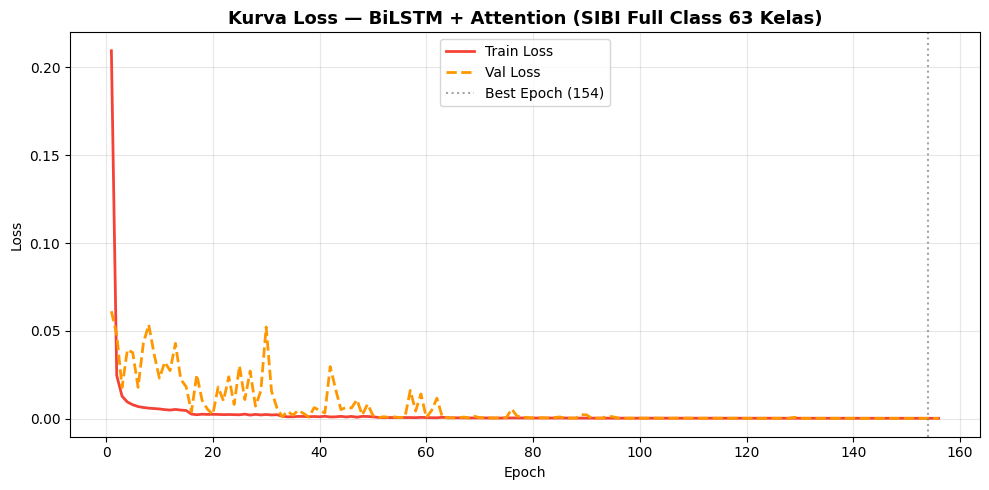

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
epochs_range = range(1, len(history.history['loss']) + 1)

ax.plot(epochs_range, history.history['loss'],
        color='#F44336', linewidth=2, label='Train Loss')
ax.plot(epochs_range, history.history['val_loss'],
        color='#FF9800', linewidth=2, linestyle='--', label='Val Loss')
best_ep = np.argmin(history.history['val_loss']) + 1
ax.axvline(x=best_ep, color='gray', linestyle=':', alpha=0.7,
           label=f'Best Epoch ({best_ep})')
ax.set_title('Kurva Loss — BiLSTM + Attention (SIBI Full Class 63 Kelas)', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_loss.png', dpi=150, bbox_inches='tight')
plt.show()

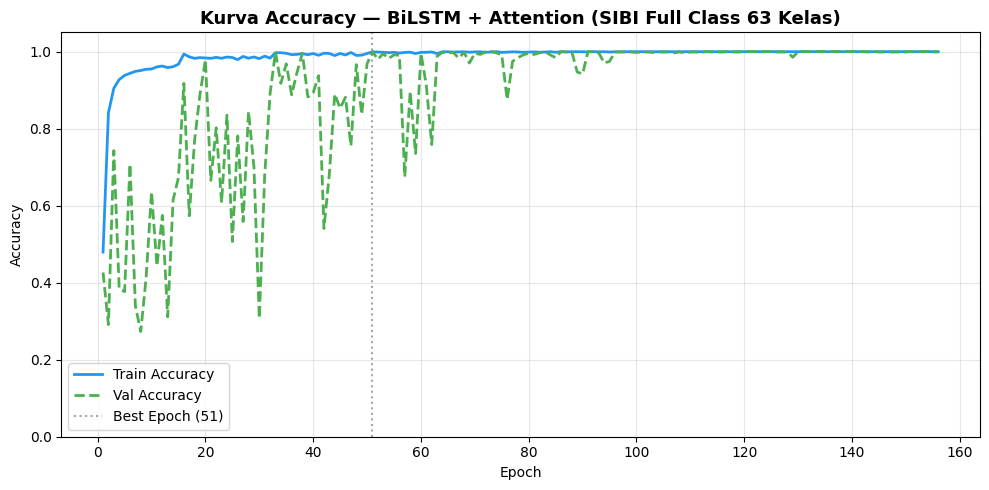

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(epochs_range, history.history['accuracy'],
        color='#2196F3', linewidth=2, label='Train Accuracy')
ax.plot(epochs_range, history.history['val_accuracy'],
        color='#4CAF50', linewidth=2, linestyle='--', label='Val Accuracy')
best_ep_acc = np.argmax(history.history['val_accuracy']) + 1
ax.axvline(x=best_ep_acc, color='gray', linestyle=':', alpha=0.7,
           label=f'Best Epoch ({best_ep_acc})')
ax.set_title('Kurva Accuracy — BiLSTM + Attention (SIBI Full Class 63 Kelas)', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy'); ax.set_ylim(0, 1.05)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()

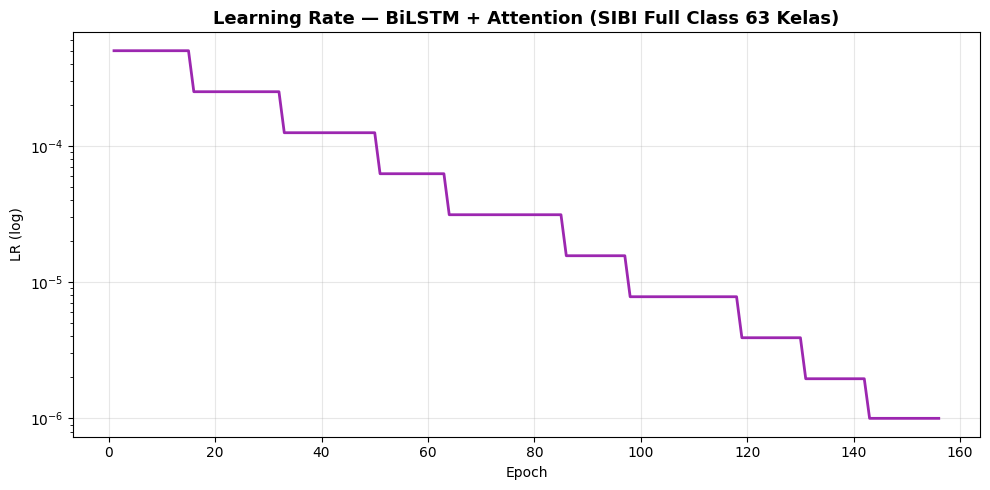

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))

if 'learning_rate' in history.history:
    ax.plot(epochs_range, history.history['learning_rate'],
            color='#9C27B0', linewidth=2)
    ax.set_yscale('log')
    ax.set_title('Learning Rate — BiLSTM + Attention (SIBI Full Class 63 Kelas)', fontsize=13, fontweight='bold')
    ax.set_xlabel('Epoch'); ax.set_ylabel('LR (log)')
    ax.grid(alpha=0.3)
else:
    ax.text(0.5, 0.5, 'LR history\ntidak tersedia',
            ha='center', va='center', transform=ax.transAxes)
    ax.set_title('Learning Rate — BiLSTM + Attention (SIBI Full Class 63 Kelas)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_learning_rate.png', dpi=150, bbox_inches='tight')
plt.show()

In [16]:
loss, acc = best_model.evaluate(X_test, y_test, verbose=0)
print('=' * 50)
print(f'  TEST ACCURACY : {acc * 100:.2f}%')
print(f'  TEST LOSS     : {loss:.4f}')
print('=' * 50)

y_pred_prob = best_model.predict(X_test, verbose=0)
y_pred      = np.argmax(y_pred_prob, axis=1)
y_true      = np.argmax(y_test,      axis=1)

print('\nClassification Report:')
print(classification_report(y_true, y_pred, target_names=actions))

report_str = classification_report(y_true, y_pred, target_names=actions)
with open(f'{PATH_CONFIGURATION_GENERAL}/classification_report.txt', 'w') as f:
    f.write(f"Test Accuracy : {acc*100:.2f}%\n")
    f.write(f"Test Loss     : {loss:.4f}\n\n")
    f.write(report_str)
print("✅ Classification report tersimpan")

  TEST ACCURACY : 99.68%
  TEST LOSS     : 0.0004

Classification Report:
              precision    recall  f1-score   support

        Adik       0.94      1.00      0.97        15
         Apa       1.00      1.00      1.00        15
        Ayah       1.00      1.00      1.00        14
        Baik       1.00      1.00      1.00        15
      Berapa       1.00      1.00      1.00        15
     Bertemu       1.00      1.00      1.00        15
      Cantik       1.00      1.00      1.00        15
        Dari       1.00      1.00      1.00        15
         Dia       1.00      1.00      1.00        15
      Dimana       1.00      1.00      1.00        15
     Ganteng       1.00      1.00      1.00        15
       Gemuk       1.00      1.00      1.00        15
       Hallo       1.00      1.00      1.00        15
        Hobi       1.00      0.93      0.97        15
         Ibu       1.00      0.93      0.97        15
       Jumat       1.00      1.00      1.00        16
     Ju

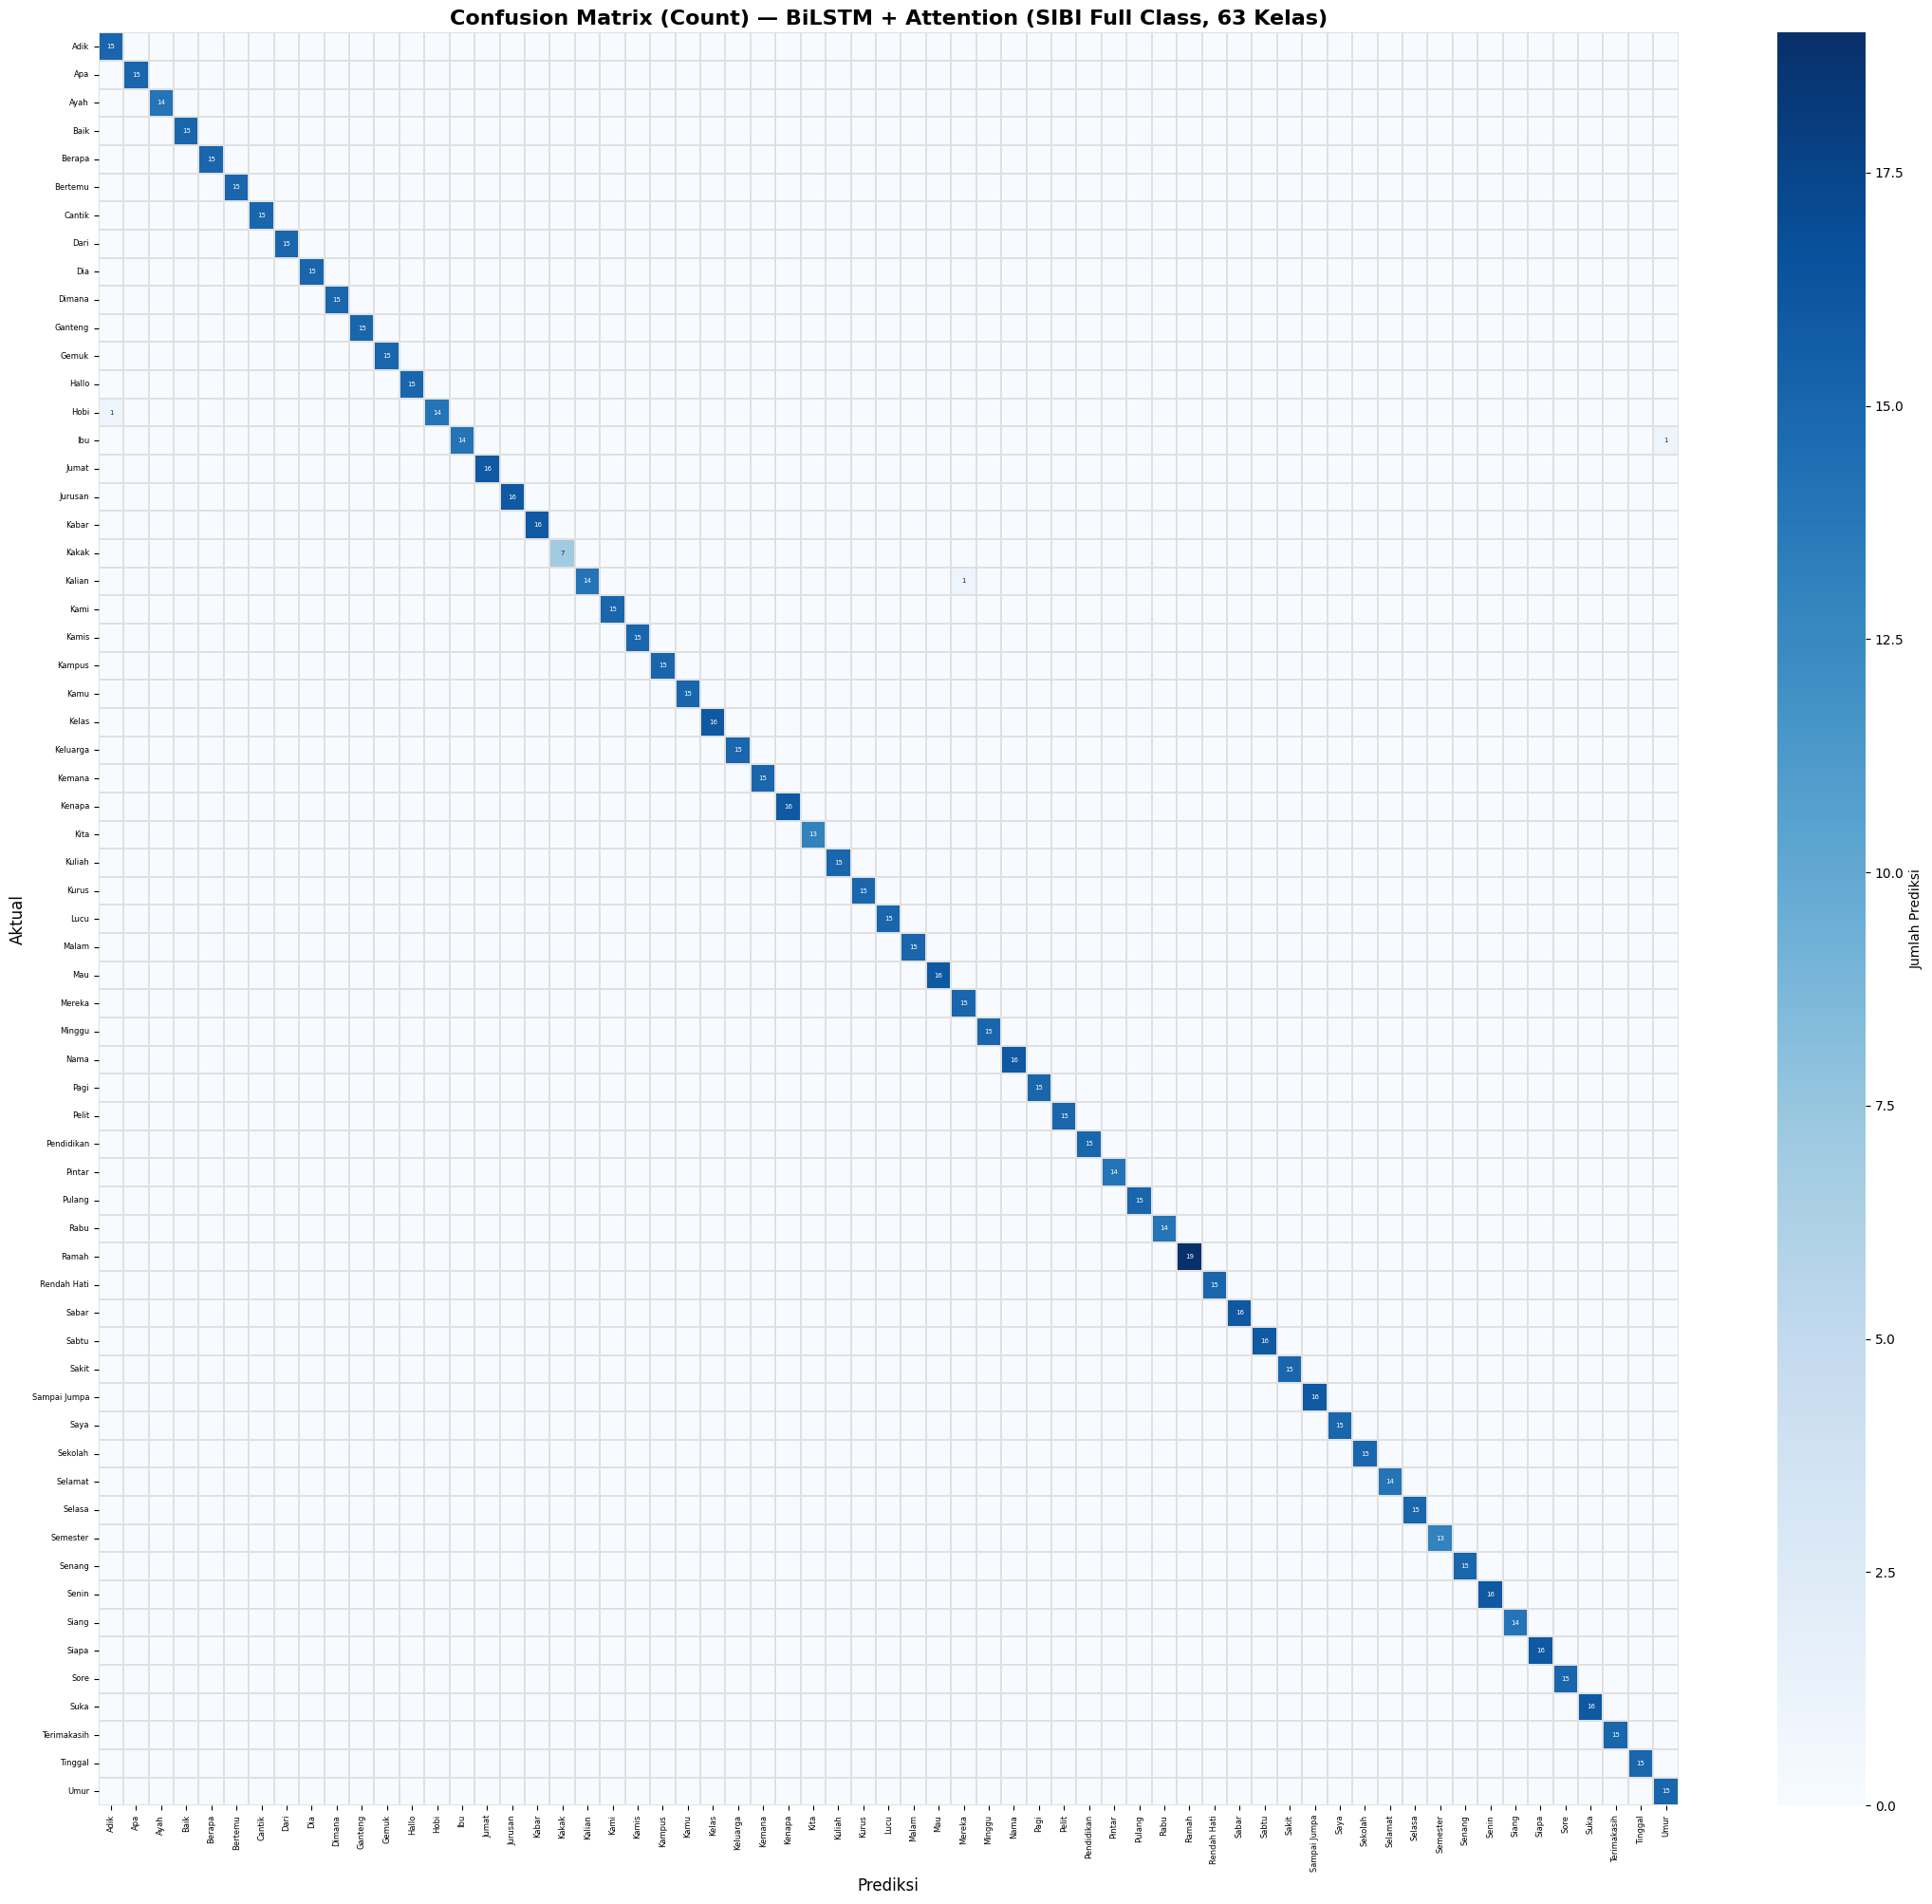

In [17]:
n = len(actions)
cm = confusion_matrix(y_true, y_pred)

# Sembunyikan angka di sel bernilai 0 agar heatmap 63x63 terbaca bersih
annot_labels = np.where(cm == 0, '', cm.astype(str))

fig, ax = plt.subplots(figsize=(max(16, n * 0.35), max(14, n * 0.32)))
sns.heatmap(cm, annot=annot_labels, fmt='', cmap='Blues',
            xticklabels=actions, yticklabels=actions, ax=ax,
            linewidths=0.3, linecolor='#E0E0E0',
            annot_kws={'fontsize': max(5, min(8, 320 / n))},
            cbar_kws={'label': 'Jumlah Prediksi'})

ax.set_title(f'Confusion Matrix (Count) — BiLSTM + Attention (SIBI Full Class, {n} Kelas)',
             fontweight='bold', fontsize=16)
ax.set_xlabel('Prediksi', fontsize=12); ax.set_ylabel('Aktual', fontsize=12)

tick_fontsize = max(6, min(9, 360 / n))
plt.xticks(rotation=90, ha='center', fontsize=tick_fontsize)
plt.yticks(rotation=0, fontsize=tick_fontsize)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_confusion_matrix_count.png', dpi=250, bbox_inches='tight')
plt.show()

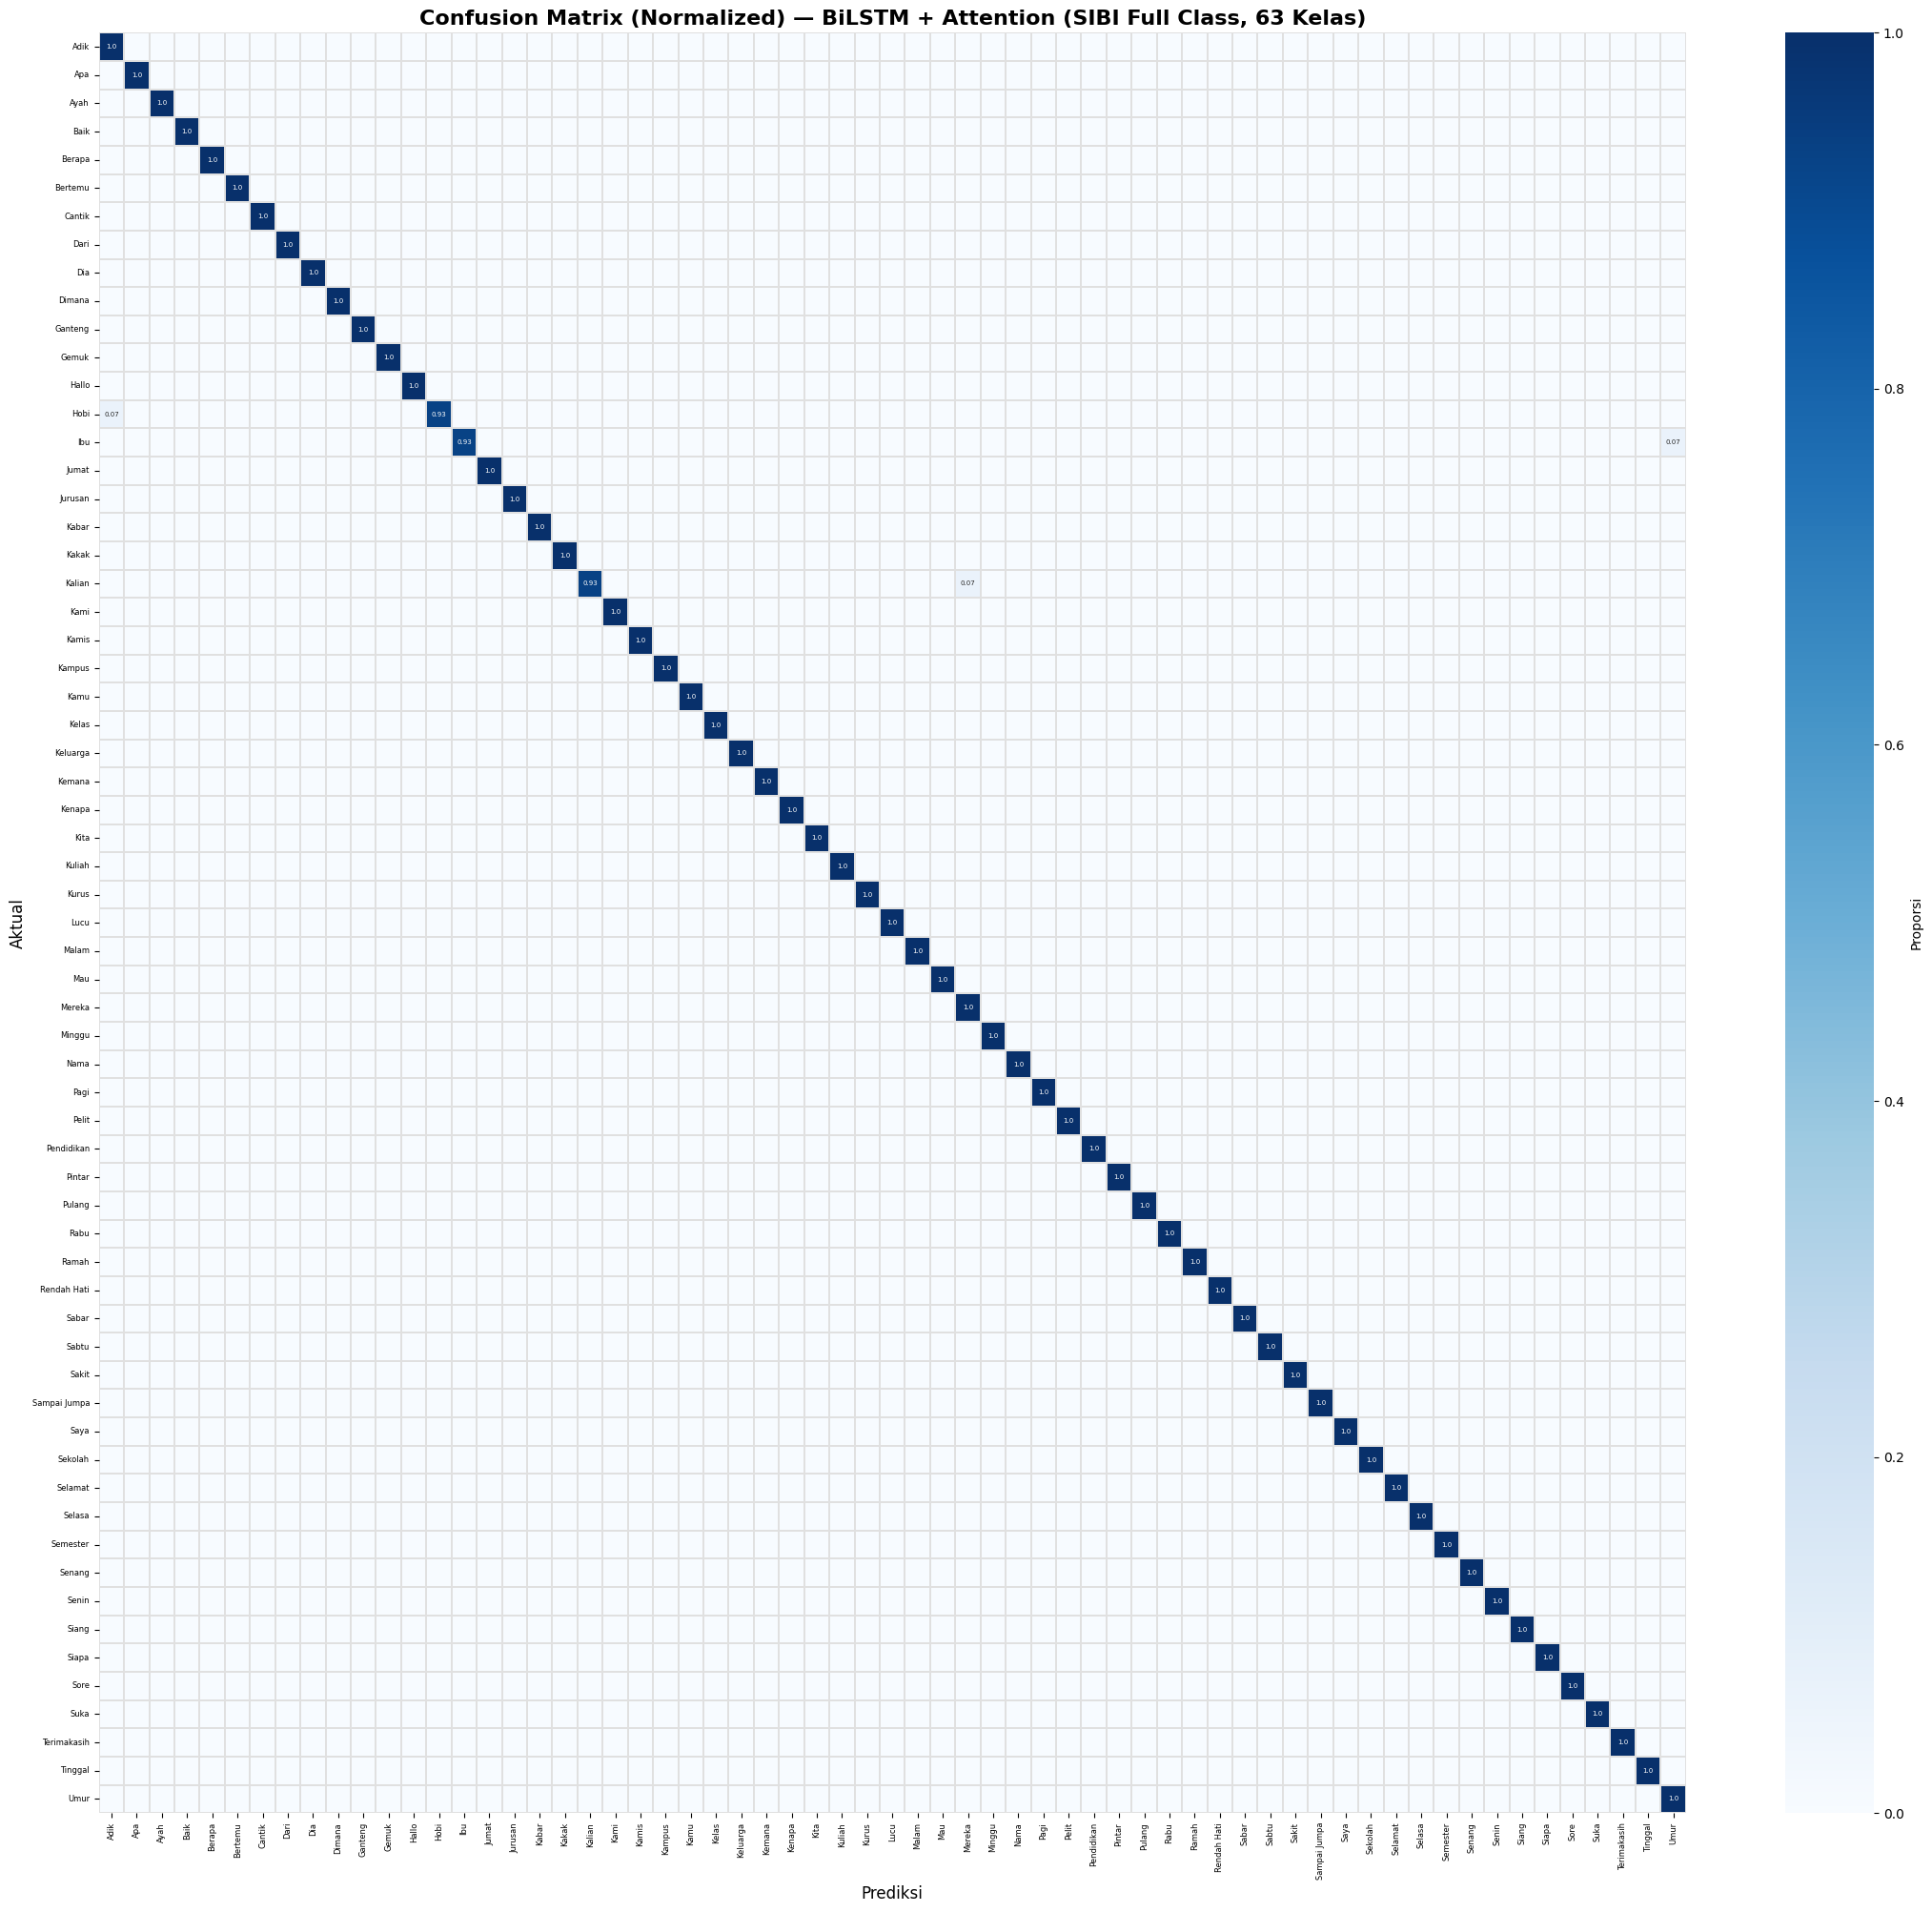

In [18]:
n = len(actions)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Sembunyikan angka di sel bernilai 0
annot_labels_norm = np.where(cm == 0, '', np.round(cm_norm, 2).astype(str))

fig, ax = plt.subplots(figsize=(max(16, n * 0.35), max(14, n * 0.32)))
sns.heatmap(cm_norm, annot=annot_labels_norm, fmt='', cmap='Blues',
            xticklabels=actions, yticklabels=actions, ax=ax,
            linewidths=0.3, linecolor='#E0E0E0',
            annot_kws={'fontsize': max(5, min(8, 320 / n))},
            cbar_kws={'label': 'Proporsi'})

ax.set_title(f'Confusion Matrix (Normalized) — BiLSTM + Attention (SIBI Full Class, {n} Kelas)',
             fontweight='bold', fontsize=16)
ax.set_xlabel('Prediksi', fontsize=12); ax.set_ylabel('Aktual', fontsize=12)

plt.xticks(rotation=90, ha='center', fontsize=tick_fontsize)
plt.yticks(rotation=0, fontsize=tick_fontsize)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_confusion_matrix_normalized.png', dpi=250, bbox_inches='tight')
plt.show()

In [19]:
print('\n⚠️  Confusable Pairs:')
for i in range(len(actions)):
    for j in range(len(actions)):
        if i != j and cm[i][j] > 0:
            print(f'  {actions[i]} → diprediksi {actions[j]}: {cm[i][j]} kali')


⚠️  Confusable Pairs:
  Hobi → diprediksi Adik: 1 kali
  Ibu → diprediksi Umur: 1 kali
  Kalian → diprediksi Mereka: 1 kali


In [20]:
report    = classification_report(y_true, y_pred,
                                   target_names=actions, output_dict=True)
df_report = pd.DataFrame(report).transpose().loc[actions]

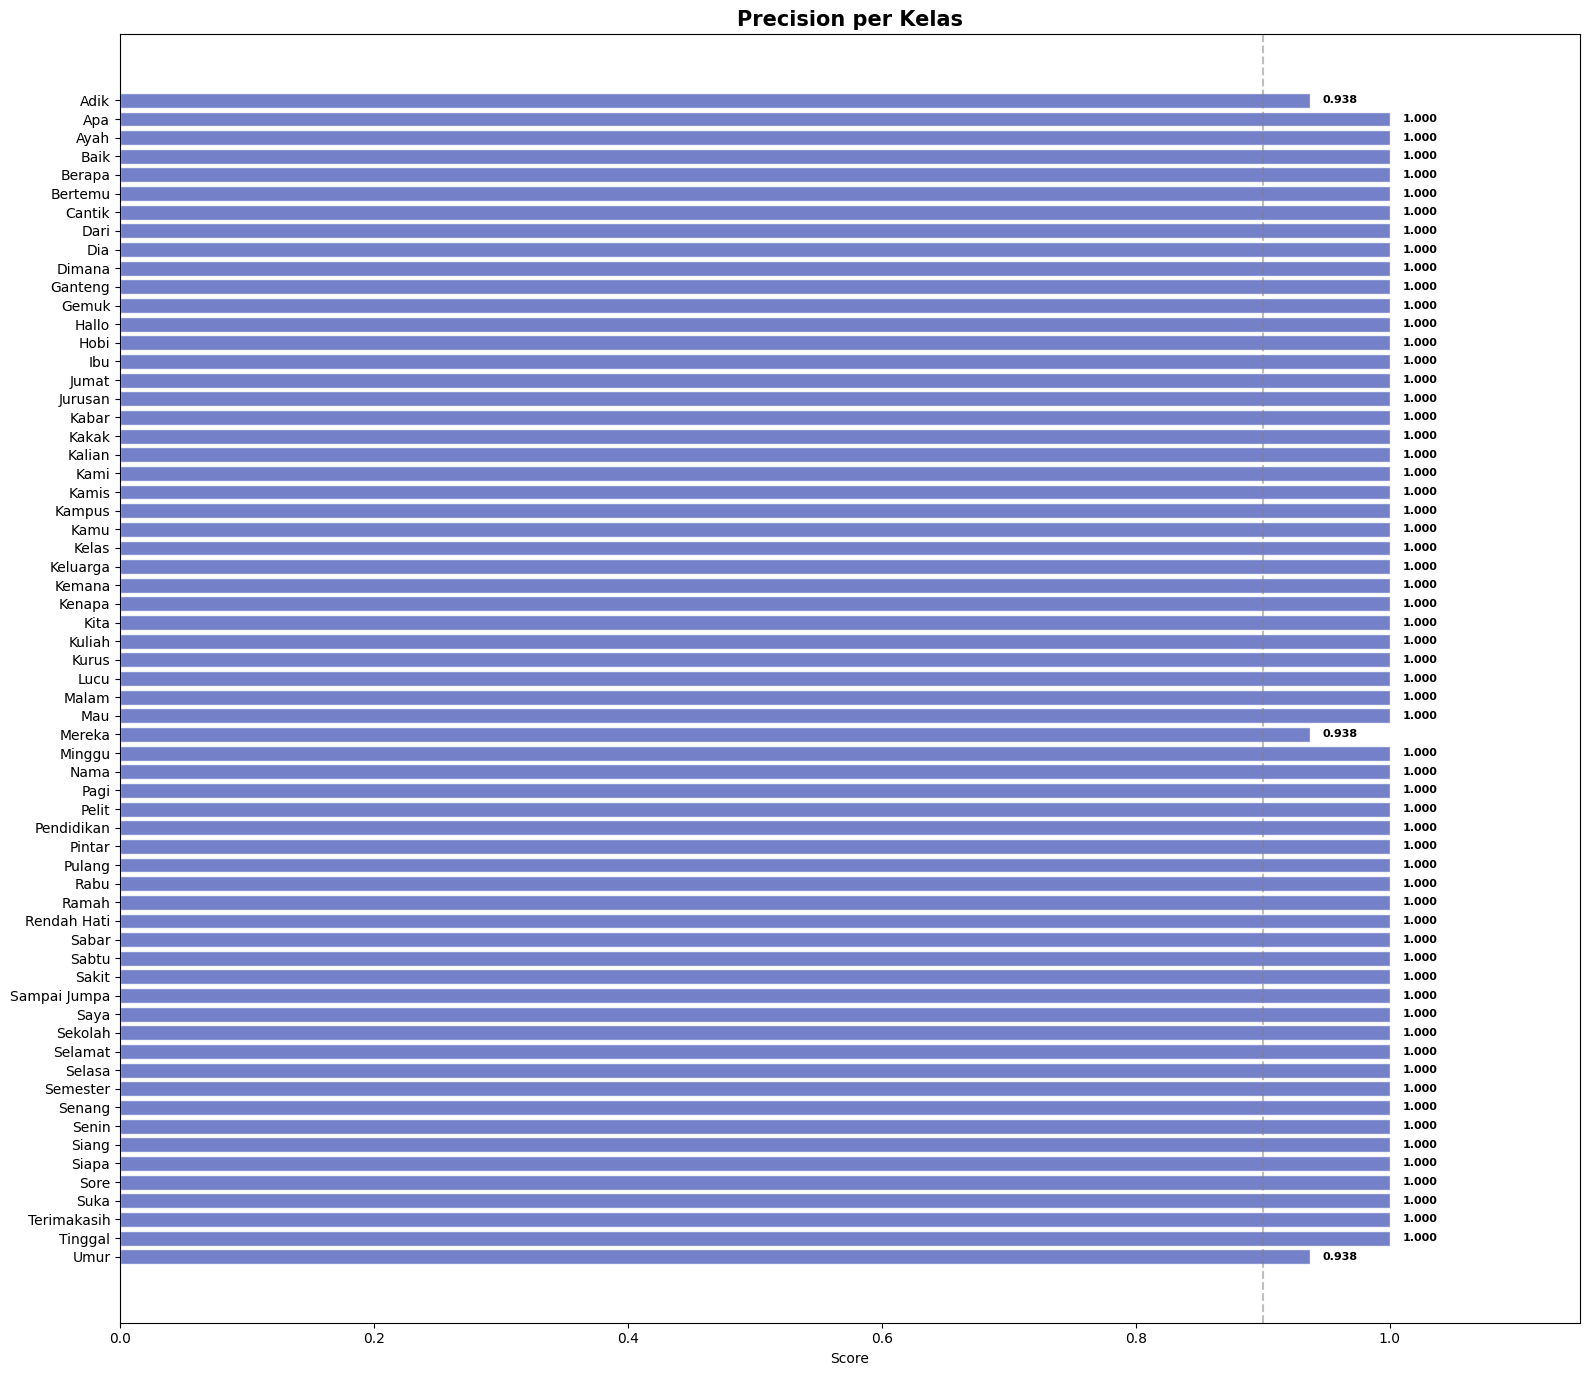

In [21]:
n = len(actions)
fig, ax = plt.subplots(figsize=(16, max(10, n * 0.22)))
vals = df_report['precision'].values
bars = ax.barh(actions, vals, color='#5C6BC0', alpha=0.85, edgecolor='white')
ax.set_title('Precision per Kelas', fontweight='bold', fontsize=15)
ax.set_xlabel('Score')
ax.set_xlim(0, 1.15)
ax.axvline(x=0.9, color='gray', linestyle='--', alpha=0.5)
ax.invert_yaxis()

for bar, v in zip(bars, vals):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
            f'{v:.3f}', va='center', fontweight='bold', fontsize=8)

plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_precision.png', dpi=200, bbox_inches='tight')
plt.show()

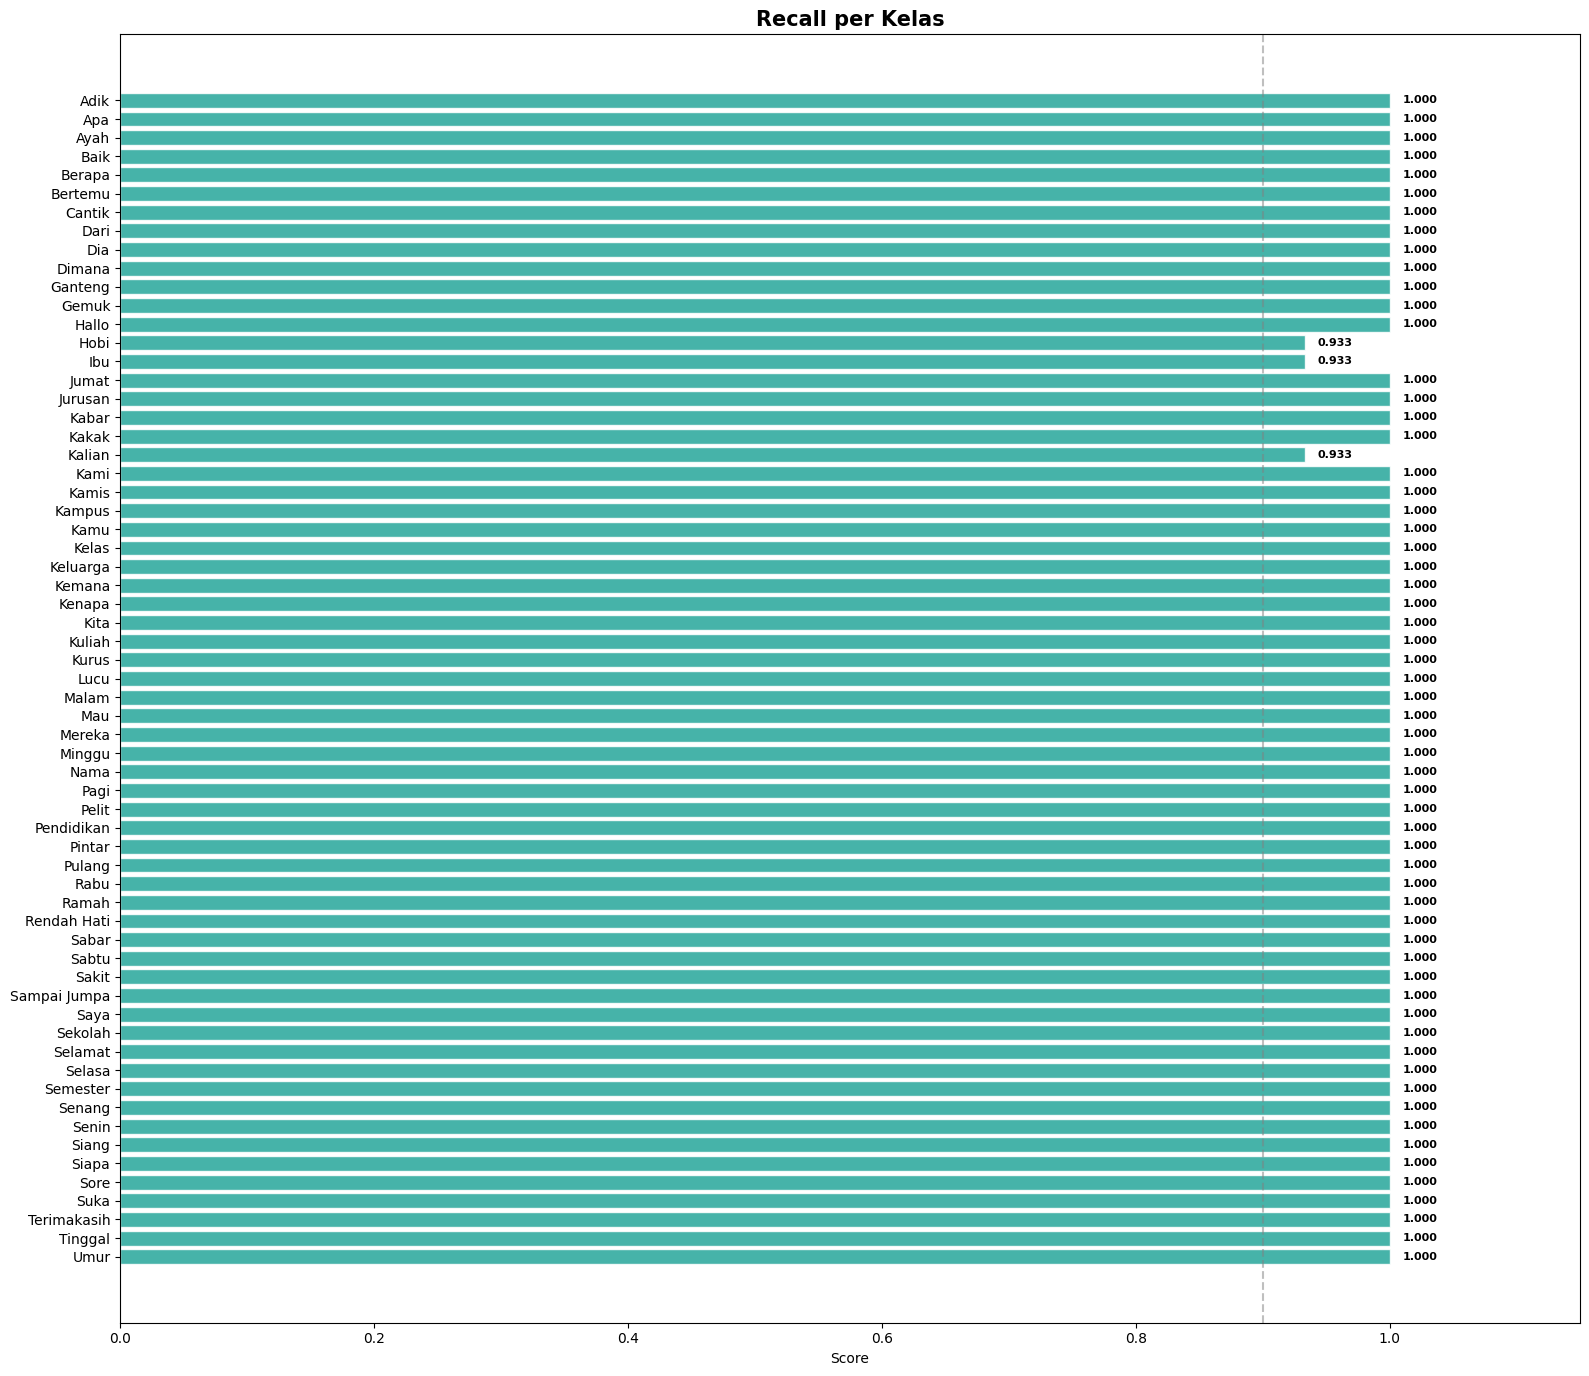

In [22]:
n = len(actions)
fig, ax = plt.subplots(figsize=(16, max(10, n * 0.22)))
vals = df_report['recall'].values
bars = ax.barh(actions, vals, color='#26A69A', alpha=0.85, edgecolor='white')
ax.set_title('Recall per Kelas', fontweight='bold', fontsize=15)
ax.set_xlabel('Score')
ax.set_xlim(0, 1.15)
ax.axvline(x=0.9, color='gray', linestyle='--', alpha=0.5)
ax.invert_yaxis()

for bar, v in zip(bars, vals):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
            f'{v:.3f}', va='center', fontweight='bold', fontsize=8)

plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_recall.png', dpi=200, bbox_inches='tight')
plt.show()

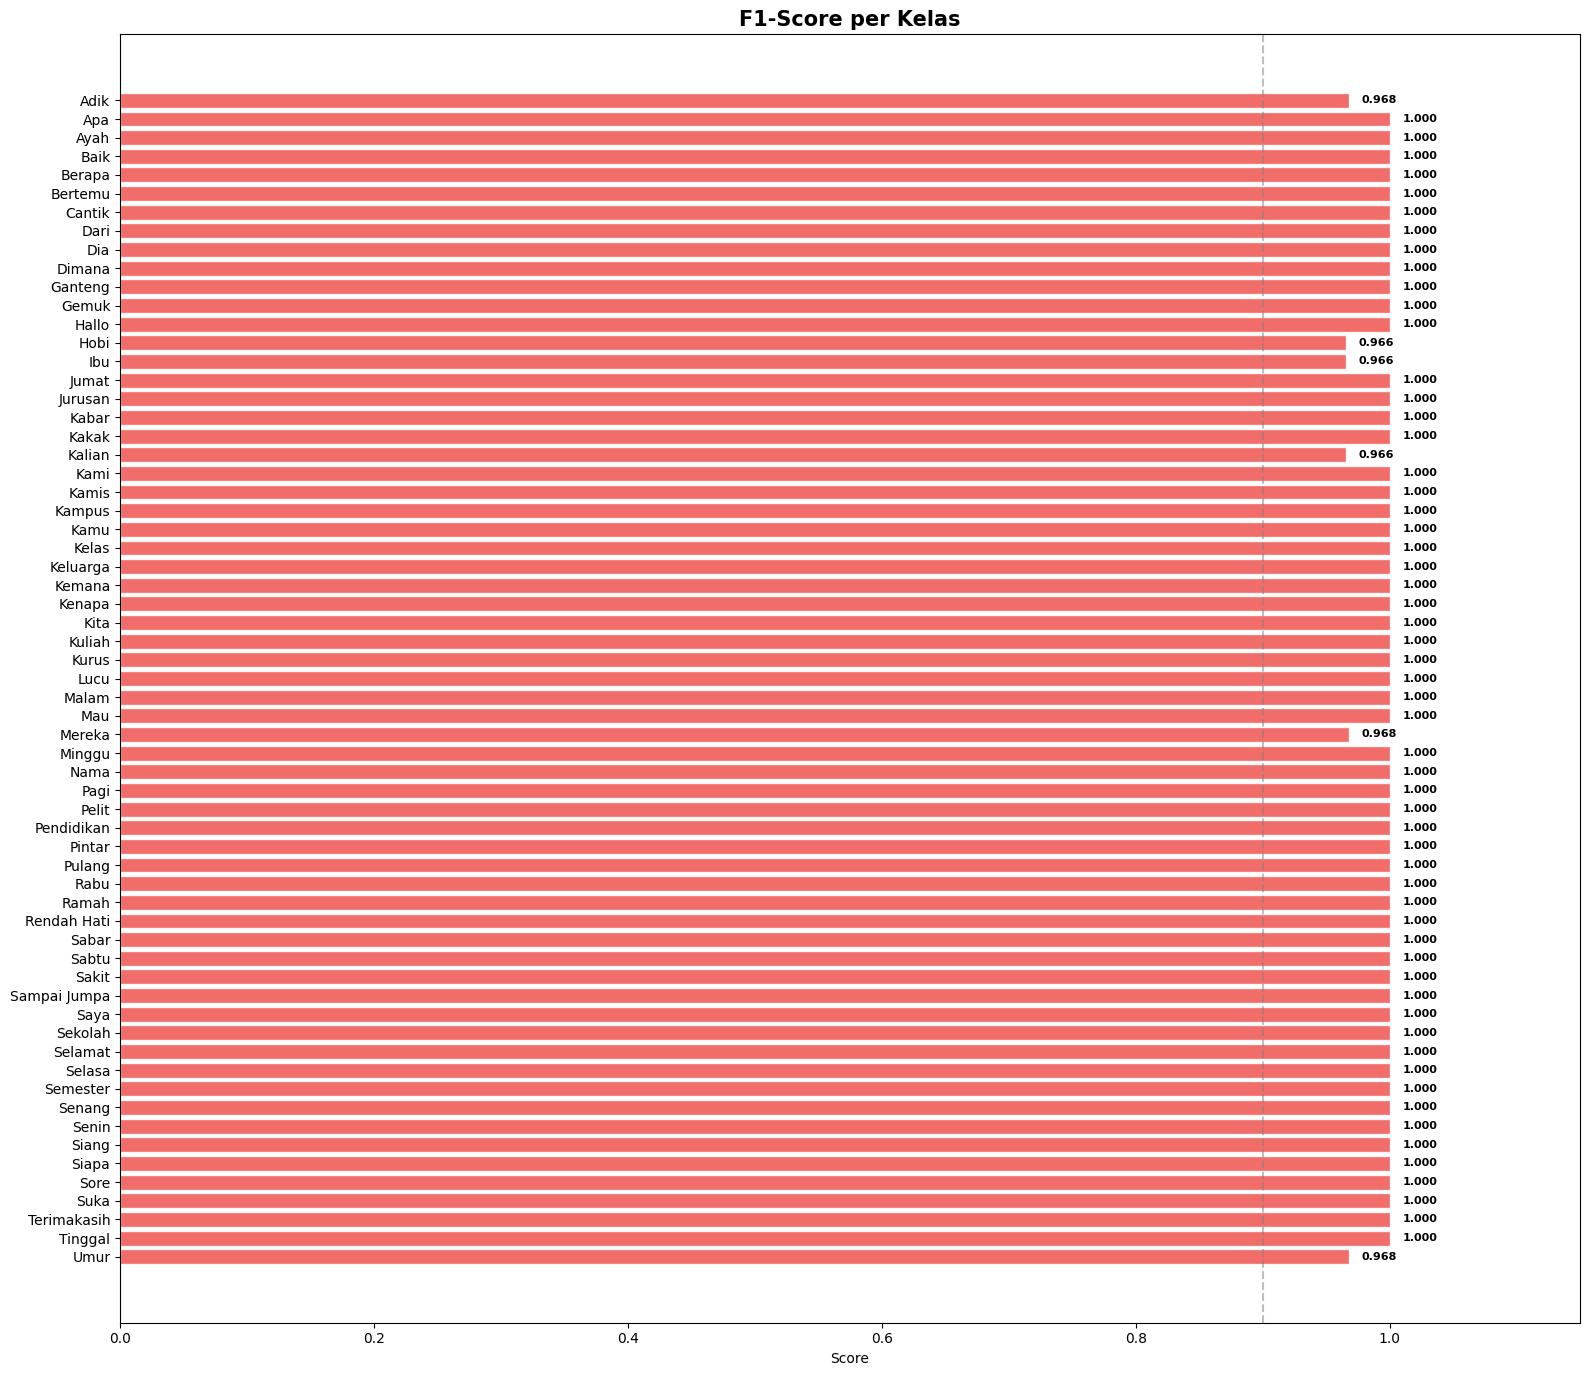

In [23]:
n = len(actions)
fig, ax = plt.subplots(figsize=(16, max(10, n * 0.22)))
vals = df_report['f1-score'].values
bars = ax.barh(actions, vals, color='#EF5350', alpha=0.85, edgecolor='white')
ax.set_title('F1-Score per Kelas', fontweight='bold', fontsize=15)
ax.set_xlabel('Score')
ax.set_xlim(0, 1.15)
ax.axvline(x=0.9, color='gray', linestyle='--', alpha=0.5)
ax.invert_yaxis()

for bar, v in zip(bars, vals):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
            f'{v:.3f}', va='center', fontweight='bold', fontsize=8)

plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_f1score.png', dpi=200, bbox_inches='tight')
plt.show()

In [24]:
print(df_report[['precision','recall','f1-score','support']].to_string())

              precision    recall  f1-score  support
Adik             0.9375  1.000000  0.967742     15.0
Apa              1.0000  1.000000  1.000000     15.0
Ayah             1.0000  1.000000  1.000000     14.0
Baik             1.0000  1.000000  1.000000     15.0
Berapa           1.0000  1.000000  1.000000     15.0
Bertemu          1.0000  1.000000  1.000000     15.0
Cantik           1.0000  1.000000  1.000000     15.0
Dari             1.0000  1.000000  1.000000     15.0
Dia              1.0000  1.000000  1.000000     15.0
Dimana           1.0000  1.000000  1.000000     15.0
Ganteng          1.0000  1.000000  1.000000     15.0
Gemuk            1.0000  1.000000  1.000000     15.0
Hallo            1.0000  1.000000  1.000000     15.0
Hobi             1.0000  0.933333  0.965517     15.0
Ibu              1.0000  0.933333  0.965517     15.0
Jumat            1.0000  1.000000  1.000000     16.0
Jurusan          1.0000  1.000000  1.000000     16.0
Kabar            1.0000  1.000000  1.000000   

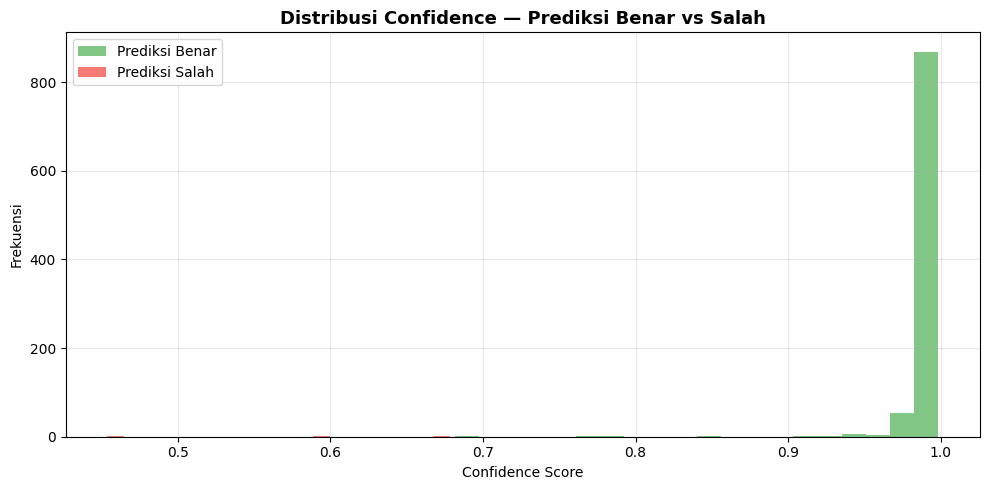

Confidence rata-rata benar : 0.9899
Confidence rata-rata salah : 0.5760


In [25]:
max_conf   = np.max(y_pred_prob, axis=1)
is_correct = (y_pred == y_true)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(max_conf[is_correct],  bins=20, alpha=0.7,
        color='#4CAF50', label='Prediksi Benar')
ax.hist(max_conf[~is_correct], bins=20, alpha=0.7,
        color='#F44336', label='Prediksi Salah')
ax.set_title('Distribusi Confidence — Prediksi Benar vs Salah', fontweight='bold', fontsize=13)
ax.set_xlabel('Confidence Score'); ax.set_ylabel('Frekuensi')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_confidence_histogram.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Confidence rata-rata benar : {max_conf[is_correct].mean():.4f}')
print(f'Confidence rata-rata salah : {max_conf[~is_correct].mean():.4f}')

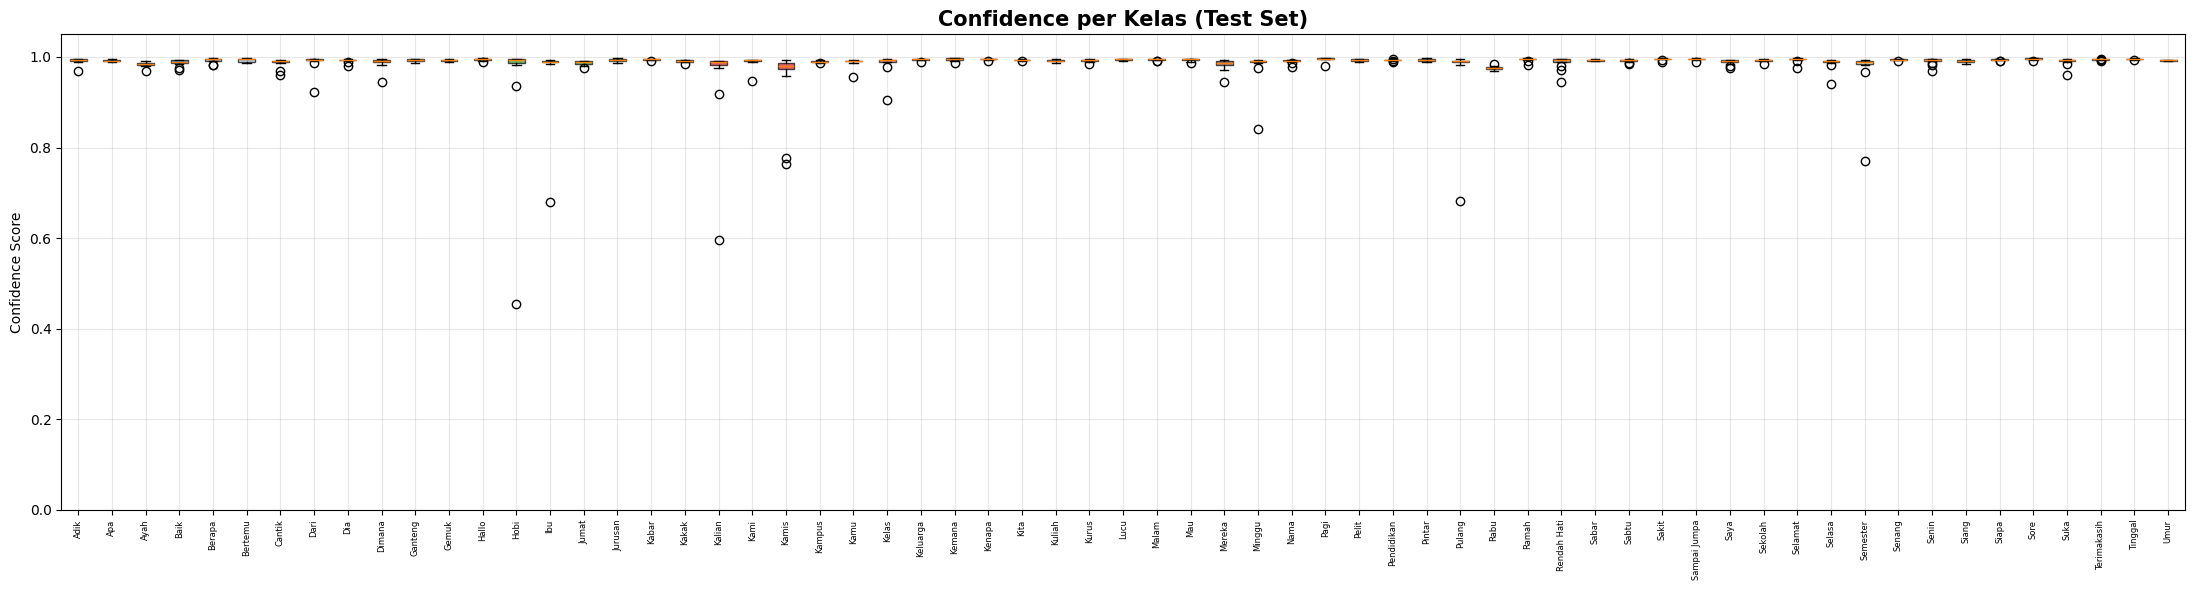

In [26]:
fig, ax = plt.subplots(figsize=(max(14, len(actions) * 0.35), 6))

bp = ax.boxplot(
    [max_conf[y_true == i] for i in range(len(actions))],
    labels=actions, patch_artist=True
)
colors_cycle = plt.cm.tab20(np.linspace(0, 1, len(actions)))
for patch, color in zip(bp['boxes'], colors_cycle):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_title('Confidence per Kelas (Test Set)', fontweight='bold', fontsize=15)
ax.set_ylabel('Confidence Score')
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
plt.xticks(rotation=90, ha='center', fontsize=max(6, min(9, 360 / len(actions))))
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_confidence_per_class.png', dpi=200, bbox_inches='tight')
plt.show()

In [27]:
report_full = classification_report(
    y_true, y_pred, target_names=actions, output_dict=True
)

print('=' * 60)
print('        RINGKASAN HASIL TRAINING — SIBI FULL CLASS — 63 KELAS (v2)')
print('=' * 60)
print(f'  Arsitektur    : BiLSTM + Attention + Focal Loss + Label Smoothing')
print(f'  Kelas         : {", ".join(actions)}')
print(f'  Total data    : {X.shape[0]} (asli) → train diaugmentasi')
print(f'  Fitur/frame   : {FITUR_PER_FRAME}')
print(f'  Sequence len  : {sequence_length} frame @ 30fps = {sequence_length/30:.1f} detik')
print('-' * 60)
print(f'  Train (aug) / Val / Test : {X_train.shape[0]} / {X_val.shape[0]} / {X_test.shape[0]}')
print('-' * 60)
print(f'  Test Accuracy : {acc * 100:.2f}%')
print(f'  Test Loss     : {loss:.4f}')
print(f'  Macro F1      : {report_full["macro avg"]["f1-score"]:.4f}')
print(f'  Weighted F1   : {report_full["weighted avg"]["f1-score"]:.4f}')
print('-' * 60)
print('  Per-Class:')
for action in actions:
    r = report_full[action]
    print(f'  {action:12s}  P={r["precision"]:.3f}  '
          f'R={r["recall"]:.3f}  F1={r["f1-score"]:.3f}')
print('=' * 60)
print(f'\n✅ Output model  : {MODEL_OUTPUT}')

with open(f'{PATH_CONFIGURATION_GENERAL}/ringkasan_training.txt', 'w', encoding='utf-8') as f:
    f.write('=' * 60 + '\n')
    f.write('        RINGKASAN HASIL TRAINING — SIBI FULL CLASS — 63 KELAS (v2)\n')
    f.write('=' * 60 + '\n')
    f.write(f'  Arsitektur    : BiLSTM + Attention + Focal Loss + Label Smoothing\n')
    f.write(f'  Kelas         : {", ".join(actions)}\n')
    f.write(f'  Jumlah Kelas  : {len(actions)}\n')
    f.write(f'  Total data    : {X.shape[0]} (asli) → train diaugmentasi\n')
    f.write(f'  Fitur/frame   : {FITUR_PER_FRAME}\n')
    f.write(f'  Sequence len  : {sequence_length} frame @ 30fps = {sequence_length/30:.1f} detik\n')
    f.write('-' * 60 + '\n')
    f.write(f'  Train (aug) / Val / Test : {X_train.shape[0]} / {X_val.shape[0]} / {X_test.shape[0]}\n')
    f.write('-' * 60 + '\n')
    f.write(f'  Test Accuracy : {acc * 100:.2f}%\n')
    f.write(f'  Test Loss     : {loss:.4f}\n')
    f.write(f'  Macro F1      : {report_full["macro avg"]["f1-score"]:.4f}\n')
    f.write(f'  Weighted F1   : {report_full["weighted avg"]["f1-score"]:.4f}\n')
    f.write(f'  Macro P       : {report_full["macro avg"]["precision"]:.4f}\n')
    f.write(f'  Macro R       : {report_full["macro avg"]["recall"]:.4f}\n')
    f.write('-' * 60 + '\n')
    f.write(f'  Epoch terbaik (val_accuracy) : {np.argmax(history.history["val_accuracy"]) + 1}\n')
    f.write(f'  Epoch terbaik (val_loss)     : {np.argmin(history.history["val_loss"]) + 1}\n')
    f.write(f'  Total epoch berjalan         : {len(history.history["loss"])}\n')
    f.write(f'  Val Accuracy terbaik         : {max(history.history["val_accuracy"]) * 100:.2f}%\n')
    f.write(f'  Val Loss terbaik             : {min(history.history["val_loss"]):.4f}\n')
    f.write('-' * 60 + '\n')
    f.write('  Per-Class Metrics:\n')
    f.write(f'  {"Kelas":<14} {"Precision":>10} {"Recall":>10} {"F1-Score":>10} {"Support":>10}\n')
    f.write('  ' + '-' * 50 + '\n')
    for action in actions:
        r = report_full[action]
        f.write(f'  {action:<14} {r["precision"]:>10.4f} {r["recall"]:>10.4f} '
                f'{r["f1-score"]:>10.4f} {int(r["support"]):>10}\n')
    f.write('-' * 60 + '\n')
    f.write('=' * 60 + '\n')

print('✅ Ringkasan tersimpan : ringkasan_training.txt')

        RINGKASAN HASIL TRAINING — SIBI FULL CLASS — 63 KELAS (v2)
  Arsitektur    : BiLSTM + Attention + Focal Loss + Label Smoothing
  Kelas         : Adik, Apa, Ayah, Baik, Berapa, Bertemu, Cantik, Dari, Dia, Dimana, Ganteng, Gemuk, Hallo, Hobi, Ibu, Jumat, Jurusan, Kabar, Kakak, Kalian, Kami, Kamis, Kampus, Kamu, Kelas, Keluarga, Kemana, Kenapa, Kita, Kuliah, Kurus, Lucu, Malam, Mau, Mereka, Minggu, Nama, Pagi, Pelit, Pendidikan, Pintar, Pulang, Rabu, Ramah, Rendah Hati, Sabar, Sabtu, Sakit, Sampai Jumpa, Saya, Sekolah, Selamat, Selasa, Semester, Senang, Senin, Siang, Siapa, Sore, Suka, Terimakasih, Tinggal, Umur
  Total data    : 6299 (asli) → train diaugmentasi
  Fitur/frame   : 258
  Sequence len  : 30 frame @ 30fps = 1.0 detik
------------------------------------------------------------
  Train (aug) / Val / Test : 39681 / 945 / 945
------------------------------------------------------------
  Test Accuracy : 99.68%
  Test Loss     : 0.0004
  Macro F1      : 0.9968
  Weighted 

In [28]:
# ==============================================================================
# SIMPAN DOKUMENTASI KELAS YANG DILATIH KE FILE .MD (MARKDOWN)
# ==============================================================================
import os
from datetime import datetime

MD_OUTPUT_PATH = f'{PATH_CONFIGURATION_GENERAL}/daftar_kelas.md'
waktu_training = datetime.now().strftime('%Y-%m-%d %H:%M:%S')

# Hitung statistik data per kelas
train_raw_counts = dict(zip(*np.unique(y_train_raw, return_counts=True)))
val_raw_counts   = dict(zip(*np.unique(y_val_raw, return_counts=True)))
test_raw_counts  = dict(zip(*np.unique(y_test_raw, return_counts=True)))
train_aug_counts = dict(zip(*np.unique(y_train_int, return_counts=True)))

md_content = f"""# Dokumentasi Model SIBI Recognition — {len(actions)} Kelas

> Dokumen ini dibuat otomatis pada akhir proses training untuk mencatat seluruh kelas kata yang dilatih pada sesi ini.

---

### 📌 Ringkasan Informasi Sesi Training
* **Waktu Selesai Training** : `{waktu_training}`
* **Jumlah Kelas**          : **{len(actions)} kata**
* **Arsitektur Model**       : BiLSTM (96 $\\rightarrow$ 64) + Attention Layer + Focal Loss + Label Smoothing
* **Dimensi Input**          : `(None, {sequence_length}, {FITUR_PER_FRAME})` (30 frame @ 30fps $\\times$ 258 keypoints)
* **File Output Model**      : `{os.path.basename(MODEL_OUTPUT)}` / `{os.path.basename(MODEL_OUTPUT_H5)}`
* **Folder Output**          : `{PATH_CONFIGURATION_GENERAL}`

---

### 📊 Performa Evaluasi Model
* **Test Accuracy** : **{acc * 100:.2f}%**
* **Test Loss**     : **{loss:.4f}**
* **Macro F1-Score**: **{report_full["macro avg"]["f1-score"]:.4f}**
* **Weighted F1**   : **{report_full["weighted avg"]["f1-score"]:.4f}**
* **Data Train (Asli / Setelah Aug)** : `{len(X_train_raw)}` / `{len(X_train)}` sequence
* **Data Val (Murni)**                : `{len(X_val_raw)}` sequence
* **Data Test (Murni)**               : `{len(X_test_raw)}` sequence

---

### 📋 Daftar Lengkap Kelas Kata yang Dilatih ({len(actions)} Kelas)

| No | Label Kelas (Action) | Data Train (Asli) | Train (Augmentasi) | Val (Asli) | Test (Asli) | Precision | Recall | F1-Score | Support |
|:---:|:---|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
"""

for idx, action in enumerate(actions, 1):
    action_idx = label_map[action]
    tr_raw  = train_raw_counts.get(action_idx, 0)
    tr_aug  = train_aug_counts.get(action_idx, 0)
    vl_raw  = val_raw_counts.get(action_idx, 0)
    ts_raw  = test_raw_counts.get(action_idx, 0)
    
    r = report_full.get(action, {})
    prec = r.get("precision", 0.0)
    rec  = r.get("recall", 0.0)
    f1   = r.get("f1-score", 0.0)
    sup  = int(r.get("support", ts_raw))
    
    md_content += f"| {idx} | **{action}** | {tr_raw} | {tr_aug} | {vl_raw} | {ts_raw} | {prec:.3f} | {rec:.3f} | {f1:.3f} | {sup} |\n"

md_content += """
---

### 💡 Catatan Pipeline Augmentasi:
Model ini dilatih dengan 8 augmentasi khusus *right-hand dominant* & multi-jarak:
1. `aug_zoom_half_body` (1.40x - 2.05x zoom setengah badan khas webcam)
2. `aug_centered_scale` (0.85x - 1.35x variasi jarak natural)
3. `aug_translation` (+-8% pergeseran posisi duduk)
4. `aug_time_warp` (0.80x - 1.20x variasi kecepatan isyarat)
5. `aug_hand_dropout` (1-3 frame toleransi kedipan tracking)
6. `aug_visibility_variation` (tahan variasi visibility browser)
7. `aug_slight_rotation` (+-6 derajat kemiringan sudut webcam)
8. `aug_gaussian_noise` (noise sensor halus)
"""

with open(MD_OUTPUT_PATH, 'w', encoding='utf-8') as f:
    f.write(md_content)

print(f'✅ Berhasil menyimpan dokumentasi kelas (.md) ke:')
print(f'   {MD_OUTPUT_PATH}')


✅ Berhasil menyimpan dokumentasi kelas (.md) ke:
   Epoch500_20261029_144056/daftar_kelas.md


In [29]:
# ==============================================================================
# EKSPOR OTOMATIS KE FORMAT TENSORFLOW.JS (UNTUK FRONTEND TFJS / NEXT.JS)
# ==============================================================================
import os
import sys
import subprocess
import shutil

TFJS_OUTPUT_DIR = f'{PATH_CONFIGURATION_GENERAL}/tfjs_modelFullClass'
os.makedirs(TFJS_OUTPUT_DIR, exist_ok=True)

print(f'=== Mengekspor model Keras ke format TensorFlow.js ===')
print(f'Model input : {MODEL_OUTPUT_H5}')
print(f'Output dir  : {TFJS_OUTPUT_DIR}')

# Kumpulkan semua kandidat converter (CLI binary maupun modul Python)
commands_to_try = []

# 1. CLI converter di PATH sistem
system_conv = shutil.which('tensorflowjs_converter')
if system_conv:
    commands_to_try.append([system_conv, '--input_format=keras', MODEL_OUTPUT_H5, TFJS_OUTPUT_DIR])

# 2. CLI converter di direktori venv (Linux & Windows)
venv_converters = [
    os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'venv', 'Scripts', 'tensorflowjs_converter.exe')),
    os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'venv', 'bin', 'tensorflowjs_converter')),
    '/mnt/d/Projects/SIBI Recognition Lecturers/Backend/venv/Scripts/tensorflowjs_converter.exe',
    '/mnt/d/Projects/SIBI Recognition Lecturers/Backend/venv/bin/tensorflowjs_converter',
    'D:/Projects/SIBI Recognition Lecturers/Backend/venv/Scripts/tensorflowjs_converter.exe'
]
for p in venv_converters:
    if os.path.exists(p) and p != system_conv:
        commands_to_try.append([p, '--input_format=keras', MODEL_OUTPUT_H5, TFJS_OUTPUT_DIR])

# 3. Eksekusi via Python module: python -m tensorflowjs.converters.converter (paling kompatibel & stabil)
python_candidates = [
    sys.executable,
    os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'venv', 'Scripts', 'python.exe')),
    os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'venv', 'bin', 'python')),
    '/mnt/d/Projects/SIBI Recognition Lecturers/Backend/venv/Scripts/python.exe',
    '/mnt/d/Projects/SIBI Recognition Lecturers/Backend/venv/bin/python',
    'D:/Projects/SIBI Recognition Lecturers/Backend/venv/Scripts/python.exe'
]
for py in python_candidates:
    if os.path.exists(py):
        commands_to_try.append([py, '-m', 'tensorflowjs.converters.converter', '--input_format=keras', MODEL_OUTPUT_H5, TFJS_OUTPUT_DIR])

# Cek apakah file hasil konversi sudah ada sebelumnya (misal re-run cell)
conversion_success = os.path.exists(os.path.join(TFJS_OUTPUT_DIR, 'model.json'))
last_err = ''

if not conversion_success:
    for cmd in commands_to_try:
        try:
            print(f'Mencoba converter: {" ".join(cmd[:3])}...')
            res = subprocess.run(cmd, capture_output=True, text=True)
            if res.returncode == 0 and os.path.exists(os.path.join(TFJS_OUTPUT_DIR, 'model.json')):
                conversion_success = True
                break
            else:
                last_err = res.stderr or res.stdout
        except Exception as e:
            last_err = str(e)

if conversion_success:
    print(f'✅ Konversi berhasil!')
    print(f'   File hasil: {os.listdir(TFJS_OUTPUT_DIR)}')

    # Salin juga file dokumentasi kelas (.md) ke dalam folder TFJS
    md_file = f'{PATH_CONFIGURATION_GENERAL}/daftar_kelas.md'
    if os.path.exists(md_file):
        shutil.copy2(md_file, os.path.join(TFJS_OUTPUT_DIR, 'daftar_kelas.md'))
        print('✅ File daftar_kelas.md ikut disertakan ke paket TFJS')

    # Salin otomatis ke Frontend/public/models/tfjs_modelFullClass dan file model
    fe_candidates = [
        os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'Frontend', 'public', 'models', 'tfjs_modelFullClass')),
        os.path.abspath(os.path.join(os.getcwd(), '..', '..', '..', 'Frontend', 'public', 'models', 'tfjs_modelFullClass')),
        'D:/Projects/SIBI Recognition Lecturers/Frontend/public/models/tfjs_modelFullClass',
        '/mnt/d/Projects/SIBI Recognition Lecturers/Frontend/public/models/tfjs_modelFullClass'
    ]
    copied = False
    for fe_dir in fe_candidates:
        parent_dir = os.path.dirname(fe_dir)
        if os.path.exists(parent_dir):
            os.makedirs(fe_dir, exist_ok=True)
            for f in os.listdir(TFJS_OUTPUT_DIR):
                src_f = os.path.join(TFJS_OUTPUT_DIR, f)
                dst_f = os.path.join(fe_dir, f)
                if os.path.isfile(src_f):
                    shutil.copy2(src_f, dst_f)
            if os.path.exists(MODEL_OUTPUT_H5):
                shutil.copy2(MODEL_OUTPUT_H5, os.path.join(parent_dir, os.path.basename(MODEL_OUTPUT_H5)))
            if os.path.exists(MODEL_OUTPUT):
                shutil.copy2(MODEL_OUTPUT, os.path.join(parent_dir, os.path.basename(MODEL_OUTPUT)))
            print(f'✅ Berhasil disalin otomatis ke Frontend: {fe_dir}')
            copied = True
            break
    if not copied:
        print(f'ℹ️  Silakan salin manual isi folder {TFJS_OUTPUT_DIR} ke Frontend/public/models/tfjs_modelFullClass/')
else:
    print(f'⚠️ Konversi gagal dengan pesan:\n{last_err}')

=== Mengekspor model Keras ke format TensorFlow.js ===
Model input : Epoch500_20261029_144056/modelFullClass.h5
Output dir  : Epoch500_20261029_144056/tfjs_modelFullClass
Mencoba converter: /mnt/d/Projects/SIBI Recognition Lecturers/Backend/venv/Scripts/tensorflowjs_converter.exe --input_format=keras Epoch500_20261029_144056/modelFullClass.h5...
✅ Konversi berhasil!
   File hasil: ['group1-shard1of1.bin', 'model.json']
✅ File daftar_kelas.md ikut disertakan ke paket TFJS
✅ Berhasil disalin otomatis ke Frontend: /mnt/d/Projects/SIBI Recognition Lecturers/Frontend/public/models/tfjs_modelFullClass
